# 00 · Base experimental SVRPBench / HBG-FACS
**Piloto de desarrollo v4 · una instancia de 50, 100, 200 y 300 clientes · depósito único.**

La reconstrucción v1 resultó imposible en los cuatro tamaños al considerar ventanas **y regreso**.
La proyección v2 alteraba demasiado los horarios urbanos y queda retirada del banco de la tesis.
**V3 fue rechazado en Colab:** el caso de 50 clientes necesita al menos 13 vehículos y tiene 12.
V4 conserva geometría y flota, además del tipo de cliente y duración de ventana. El intento 0 reproduce
v3 para documentar su rechazo; los siguientes remuestrean **todas las ventanas** con el generador
oficial. Cada ventana debe pasar el filtro individual. Sólo se avanza tras una prueba de imposibilidad
conjunta; un timeout detiene el banco y conserva el caso. La población resultante es derivada y
condicionada: no recupera ventanas originales ausentes de Hugging Face.

**Ejecución exclusivamente en Colab.** Se acepta la primera muestra con una solución nominal completa
verificada, sin filtrar por costo ni factibilidad estocástica. Hasta 32 candidatos por tamaño,
120 s por fase CP-SAT (dos fases como máximo por candidato; la cota de flota puede rechazarlo antes).
Se registra progreso y se guarda cada intento en Drive. El banco sólo se sella si pasan los cuatro
tamaños; v4 está pendiente de ejecución y certificación en Colab.

Este notebook se ejecuta por sí solo en Colab: no necesita clonar el repositorio privado de la tesis.
Descarga un catálogo fijado, preserva los originales, produce derivados identificados, sella el banco
común y evalúa una heurística diagnóstica bajo escenarios compartidos. El código también se conserva
como módulo para que los notebooks siguientes importen **el mismo evaluador**.

**Entorno:** el notebook conserva la solicitud de **GPU A100 + RAM amplia**. Colab puede asignar
otra; la celda 1 muestra la GPU real. Este notebook 00 sólo usa CPU (KMeans y evaluador): para ahorrar
unidades puede elegirse CPU aquí y reservar la A100 para los entrenamientos. No se sustituye PyTorch/CUDA.

**Orden:** Entorno de ejecución → Ejecutar todo. Autorizar Drive en la celda 3. No hace falta reiniciar:
se usan las bibliotecas preinstaladas de Colab. OR-Tools y pytest se instalan sólo si faltan. La
reproducibilidad usa hashes, semillas y registros de muestreo. Los datos residen en el disco de Colab y se copian a Drive con comprobación
de integridad; no se entrena leyendo miles de archivos directamente desde Drive.

No hay pruebas de significancia en este piloto. Las instancias inspeccionadas pasan a ser desarrollo,
aunque Hugging Face las llame `test`; no podrán reutilizarse como prueba final de generalización.

## 1. Dependencias de la base
`REQUIREMENTS` conserva las versiones de referencia usadas para v1 (Python 3.12). Colab usa otras
versiones; reinstalarlas obligaba a reiniciar y degradaba `huggingface_hub`, del que dependen
`transformers` y `datasets` de Colab. Por defecto se usan las preinstaladas, sólo se instala lo ausente
y las diferencias se registran. El catálogo y la reconstrucción v1 deben coincidir con sus hashes
de referencia; si no, la ejecución se detiene y pide `STRICT_PINS = True` (instala las versiones fijadas y
reinicia la sesión una vez). RL4CO se integrará al añadir métodos; aquí se fija el contrato común.
V4 es nuevo: sus hashes se sellan al certificarse en Colab y se comprueban al reutilizarlo.

In [24]:
import sys, os, shutil, subprocess, importlib.metadata
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if not IN_COLAB:
    raise RuntimeError('Por decisión del autor, este notebook y los experimentos se ejecutan exclusivamente en Google Colab.')
SKIP_INSTALL = os.environ.get('SVRP_SKIP_INSTALL') == '1'  # verificación de dependencias sin instalar
STRICT_PINS = False  # True: instala REQUIREMENTS exactos; en Colab reinicia la sesión una vez
REQUIREMENTS = ['numpy==2.2.6', 'pandas==2.2.3', 'matplotlib==3.10.3', 'scipy==1.15.3', 'scikit-learn==1.6.1', 'pillow==11.2.1', 'tqdm==4.67.1', 'pyarrow==20.0.0', 'huggingface-hub==0.33.4']
IMPORT_NAMES = {'scikit-learn': 'sklearn', 'pillow': 'PIL', 'huggingface-hub': 'huggingface_hub'}
def installed_version(name):
    try: return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: return None
absent = [s for s in REQUIREMENTS if installed_version(s.split('==')[0]) is None]
drift = {s.split('==')[0]: installed_version(s.split('==')[0]) for s in REQUIREMENTS
         if s not in absent and installed_version(s.split('==')[0]) != s.split('==')[1]}
pending = absent + ([s for s in REQUIREMENTS if s.split('==')[0] in drift] if STRICT_PINS else [])
if pending and SKIP_INSTALL:
    raise RuntimeError(f'Entorno de prueba incompleto: {pending}')
if pending:
    loaded = [s for s in pending if IMPORT_NAMES.get(s.split('==')[0], s.split('==')[0]) in sys.modules]
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pending], check=True)
    if loaded:
        print('Versiones fijadas instaladas sobre módulos ya cargados:', loaded)
        if IN_COLAB:
            print('Colab reiniciará la sesión. Después: Entorno de ejecución → Ejecutar todo.', flush=True)
            os.kill(os.getpid(), 9)
        raise RuntimeError('Reinicia el kernel y ejecuta desde el principio.')
    drift = {} if STRICT_PINS else drift
if drift:
    print('Versiones distintas de las validadas (se usan y registran):', drift)
extra_missing = [name for name in ('ortools','pytest') if installed_version(name) is None]
if extra_missing:
    # Evita resolver OR-Tools degradando/actualizando silenciosamente el entorno principal.
    protected = ('numpy','pandas','scipy','matplotlib','pillow','huggingface-hub',
                 'protobuf','torch','transformers','datasets')
    constraints = Path('/content/svrp_dependency_constraints.txt')
    constraints.write_text(''.join(f'{name}=={installed_version(name)}\n'
        for name in protected if installed_version(name) is not None))
    subprocess.run([sys.executable,'-m','pip','install','-q','-c',str(constraints),*extra_missing],check=True)
print('Certificador OR-Tools:',installed_version('ortools'),'| pytest:',installed_version('pytest'))
print('Python', sys.version.split()[0], '| instalado:', absent or 'nada')
gpu = None
if shutil.which('nvidia-smi'):
    gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                         capture_output=True, text=True, timeout=15).stdout.strip()
print('GPU asignada:', gpu or 'ninguna (CPU)')
WORK = Path(os.environ.get('SVRP_WORK_DIR', '/content/TESIS_EHBG_FACS'))
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
print('Disco de trabajo en Colab:', WORK)

Versiones distintas de las validadas (se usan y registran): {'numpy': '2.1.3', 'matplotlib': '3.10.0', 'scipy': '1.16.3', 'pillow': '11.3.0', 'tqdm': '4.67.3', 'pyarrow': '23.0.1', 'huggingface-hub': '1.29.0'}
Certificador OR-Tools: 9.12.4544 | pytest: 8.4.2
Python 3.13.15 | instalado: nada
GPU asignada: NVIDIA A100-SXM4-80GB, 81920 MiB
Disco de trabajo en Colab: /content/TESIS_EHBG_FACS


## 2. Configuración previa a observar resultados
La elección es `instance_id=0` del subconjunto `twvrp_N_single_depot`, sin buscar la instancia donde
un método funcione mejor. 300 clientes se generan con el generador oficial. La reconstrucción de
ventanas y el tamaño 300 fueron aceptados por el autor de la tesis. Se conserva el tipo latente y la
duración de cada ventana; sólo se remuestrea si la visita individual no pasa el filtro conservador.

Los 256 escenarios de evaluación son un punto inicial de depuración (unas 13 observaciones de cola
al 95%), no una certificación de precisión. Se guardan costos crudos para ampliar M después.
Cambiar una regla genera otro banco; nunca sustituye silenciosamente el banco utilizado por otros métodos.

In [25]:
CONFIG = {'protocol_version': 'pilot-00-v4', 'role': 'development_only', 'sizes': [50, 100, 200, 300], 'instances_per_size': 1, 'selection_rule': 'first_source_instance_id_before_solver_runs', 'master_seed': 20260916, 'scenarios': {'train': 32, 'selection': 64, 'evaluation': 256}, 'alpha_cvar': 0.95, 'traffic': {'velocity': 1.0, 'noise_scale': 1.0, 'accident_scale': 1.0, 'bucket_minutes': 1.0, 'mode': 'stochastic'}, 'policies': ['fixed_order', 'causal_edd'], 'derived_windows_approved': True, 'derived_300_approved': True, 'depot_index': 0, 'service_time_minutes': 0.0, 'global_start_time_minutes': 0.0, 'latency_threshold': None, 'minimum_improvement': None, 'significance_tests_enabled': False, 'deadline_window': '2026-10-26/2026-10-31', 'enn': 'optional_exploratory', 'windows': {'policy': 'official_type_width_conditioned_reachability_v1', 'preserve_widths': True, 'preserve_customer_types': True, 'max_draws_per_customer': 10000, 'original_reconstruction_role': 'diagnostic_infeasible_archive', 'projected_v2_role': 'retired_not_thesis_population', 'certificate_role': 'quality_control_only_not_solver_input', 'joint_policy': 'joint_official_draws_proven_rejection_v1', 'max_joint_candidates': 32, 'initial_candidate': 'exact_v3_individually_conditioned', 'subsequent_candidates': 'redraw_all_customers_same_type_and_width', 'rejection_policy': 'proven_infeasibility_only', 'globally_infeasible_v3_role': 'rejected_with_proof'}, 'certification': {'seconds_per_strategy': 120, 'time_scale': 1000, 'unknown_policy': 'stop_keep_same_candidate_no_automatic_resampling', 'strategies': ['CP_SAT_OPTIMISTIC_FREE_FLOW', 'CP_SAT_CONSERVATIVE_NOMINAL_MEAN']}, 'execution_policy': 'colab_only'}
print(CONFIG)

{'protocol_version': 'pilot-00-v4', 'role': 'development_only', 'sizes': [50, 100, 200, 300], 'instances_per_size': 1, 'selection_rule': 'first_source_instance_id_before_solver_runs', 'master_seed': 20260916, 'scenarios': {'train': 32, 'selection': 64, 'evaluation': 256}, 'alpha_cvar': 0.95, 'traffic': {'velocity': 1.0, 'noise_scale': 1.0, 'accident_scale': 1.0, 'bucket_minutes': 1.0, 'mode': 'stochastic'}, 'policies': ['fixed_order', 'causal_edd'], 'derived_windows_approved': True, 'derived_300_approved': True, 'depot_index': 0, 'service_time_minutes': 0.0, 'global_start_time_minutes': 0.0, 'latency_threshold': None, 'minimum_improvement': None, 'significance_tests_enabled': False, 'deadline_window': '2026-10-26/2026-10-31', 'enn': 'optional_exploratory', 'windows': {'policy': 'official_type_width_conditioned_reachability_v1', 'preserve_widths': True, 'preserve_customer_types': True, 'max_draws_per_customer': 10000, 'original_reconstruction_role': 'diagnostic_infeasible_archive', 'pro

## 3. Google Drive
Carpeta de salida: `MyDrive/TESIS-EHBG-FACS/`. Al reabrir Colab se recupera un banco ya sellado.
La autorización de Drive la concede el usuario en el cuadro de Colab. El montaje no implica que se
hayan ejecutado experimentos ni que exista ya un resultado. Si se cancela, la celda se detiene para
no dar una falsa confirmación de persistencia.

In [26]:
USE_DRIVE = IN_COLAB
DRIVE_ROOT = None
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = Path('/content/drive/MyDrive/TESIS-EHBG-FACS')
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
    print('Destino persistente:', DRIVE_ROOT)
else:
    print('Drive desactivado: salidas temporales en el disco de Colab:', WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Destino persistente: /content/drive/MyDrive/TESIS-EHBG-FACS


## 4. Implementación común y trazable
La siguiente celda escribe `svrplab_pilot.py`. Está incluida sin ofuscación para que el notebook funcione
al subir únicamente este archivo a Colab. Su fuente editable en GitHub es `src/svrplab/pilot.py`.

**Reglas:** depósito explícito 0; clientes 1…N incluyendo demanda cero; lista por vehículo;
capacidad y cobertura duras; servicio de duración cero por falta de tiempos de servicio en la fuente;
salida a minuto 0; ventanas evaluadas al iniciar servicio; regreso al depósito antes de 1440.
Se permite terminar una ejecución con tardanzas para medirlas, pero esa ejecución es **infactible**.

In [27]:
%%writefile svrplab_pilot.py
"""Notebook 00: datos, auditoría, CRN y evaluación independiente del solver.

Adaptación del generador de tráfico de SVRPBench (MIT, Ahmed Heakl, 2024).
Ver docs/SVRPBench-LICENSE.txt y docs/NOTEBOOK_00.md para las diferencias.
No contiene entrenamiento HBG/AM/POMO ni demuestra superioridad estadística.
"""
from __future__ import annotations

import hashlib
import importlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import platform
import random
import shutil
import subprocess
import sys
import time
import urllib.request
import warnings
from contextlib import contextmanager
from dataclasses import asdict, dataclass

import numpy as np

UPSTREAM_SHA = '9fd5737ae598e1667ae94907f9c45224c501c84b'
HF_REVISION = '4a79ade38f663edaefa62e34e7c2ea330a2e15da'
ROWS_SHA = '9c055992902ddf9c6133c438bc35e09623d59b0a376b623cbadd3375bbd36147'
SOURCE_FILES = ('city.py', 'constants.py', 'common.py', 'time_windows_generator.py',
                'travel_time_generator.py', 'real_twcvrp.py')
SOURCE_HASHES = {'city.py': 'c55ef26cfbd24fa705afd6223aa45cf53094168ba02d95552562c9a66dc09e9e', 'constants.py': '28cca2aecf61bad8e4fb75dc6807f18f200998eb8a767a62e425c50641f25758', 'common.py': '8400c0e767c189987ccf26dee9688117ee2deb4e14f3c8ce516dd30e70ea5f5b', 'time_windows_generator.py': '90b19f40fdef99604345bf5935ceb40b54f10e5d869c77974bcef736a26d2afb', 'travel_time_generator.py': 'a0f6251321bcf053f251c58dd6d7ce207b7c2f66595444fdface1d54127d6e5e', 'real_twcvrp.py': '3530823c42ef6480b6d0aa63d3535b8e8313e20d82b904647653cf0c5da9de07'}
PROTOCOL_VERSION = 'pilot-00-v4'
WINDOW_POLICY = 'official_type_width_conditioned_reachability_v1'
JOINT_WINDOW_POLICY = 'joint_official_draws_proven_rejection_v1'
LEGACY_WINDOW_POLICY = 'balanced_insertion_mean_time_projection_v1'
# Candidato rechazado en Colab, comunicado por el autor; NO banco aceptado.
COLAB_REJECTED_V3_SHA = {50: 'e7390617fa2471dc120f03182eeeb9d6ea081a2ce44b8e1b390fd095e980531d'}
# Instancias validadas (master_seed, n) -> sha256. Coinciden con Python 3.12 + versiones
# fijadas y con el entorno Colab (Python 3.13, numpy 2.1.3, scikit-learn 1.6.1).
# Garantizan reproducibilidad por contenido, no por versión de biblioteca.
REFERENCE_INSTANCE_SHA = {
    (20260916, 50): '17dc741073c2b524d3bfbd97912fd4abd9ab033267faf2bc629265de9fb1f0f9',
    (20260916, 100): '540bb7187a90ef06f56f90c4a5e0cb0438bfc902d2077975fb3faa7fe914319f',
    (20260916, 200): 'fb3e12f54bd1003e00ed1910601935fe714aa561ef2feadeae90221592644445',
    (20260916, 300): '3e7cf85cf9c76b4fb10b73d013ffbc4b6ee7017d777ad1c093928be45877eec8',
}
LEGACY_V2_REFERENCE_SHA = {
    50: 'cb57f1068a3c7b173dbd087154f8276a8ba98df7cb45cc542fc8a3f5ef12b94f',
    100: '3e70717e9302373d12ddf25c613ef3c84522ba6c4f8a735c3368684db60eccff',
    200: '387948482f58d7f1e8d6c109f5edcbcc59ea318660b166119e76dc5b3f6c422c',
    300: 'd2c4b2457c08cf9fa7981fa13a85bd0637ea914ef9eb281f62acdc96f3f3b231',
}


def canonical_bytes(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'),
                      ensure_ascii=False, allow_nan=False).encode('utf-8')


def digest(value):
    return hashlib.sha256(canonical_bytes(value)).hexdigest()


def file_hash(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + '\n')
    temporary.replace(path)


def seed_for(*parts):
    return int.from_bytes(hashlib.sha256(canonical_bytes(parts)).digest()[:8], 'little')


@contextmanager
def legacy_seed(seed):
    """Aísla las RNG globales que usa el generador oficial."""
    py, np_state = random.getstate(), np.random.get_state()
    random.seed(seed)
    np.random.seed(seed % 2**32)
    try:
        yield
    finally:
        random.setstate(py)
        np.random.set_state(np_state)


def download(url, destination):
    """Descarga atómica, tiempo limitado; no ejecuta contenido descargado."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(url, headers={'User-Agent': 'SVRPLab-thesis/1.0'})
    with urllib.request.urlopen(request, timeout=90) as response:
        payload = response.read()
    temporary = destination.with_suffix(destination.suffix + '.download')
    temporary.write_bytes(payload)
    temporary.replace(destination)
    return destination


def fetch_upstream(root):
    root = Path(root)
    for name in SOURCE_FILES:
        path = root / 'vrp_bench' / name
        if not path.exists():
            download(f'https://raw.githubusercontent.com/yehias21/svrpbench/{UPSTREAM_SHA}/vrp_bench/{name}', path)
    if not (root / 'LICENSE').exists():
        download(f'https://raw.githubusercontent.com/yehias21/svrpbench/{UPSTREAM_SHA}/LICENSE', root / 'LICENSE')
    for name, expected in SOURCE_HASHES.items():
        if file_hash(root / 'vrp_bench' / name) != expected:
            raise ValueError(f'Código upstream modificado: {name}')
    # Hashes verificados; el commit completo fija las URLs.
    return {str(p.relative_to(root)): file_hash(p)
            for p in sorted(root.rglob('*')) if p.is_file() and p.suffix == '.py'}


def load_catalog(cache):
    """Parquet fijado; fallback oficial Viewer sólo si coincide el hash de 560 filas.

    La revisión del Viewer no se puede seleccionar: se identifica como snapshot
    verificado por contenido, nunca como descarga de la revisión fijada.
    """
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    snapshot = cache / 'catalog_rows.json'
    meta_file = cache / 'catalog_provenance.json'
    if snapshot.exists():
        rows = json.loads(snapshot.read_text())
        meta = json.loads(meta_file.read_text()) if meta_file.exists() else {'transport': 'local_verified_snapshot'}
    else:
        rows = None
        try:
            from huggingface_hub import hf_hub_download
            import pyarrow.parquet as pq
            path = hf_hub_download(repo_id='MBZUAI/svrp-bench',
                filename='data/test-00000-of-00001.parquet', repo_type='dataset',
                revision=HF_REVISION, local_dir=str(cache / 'hf'))
            rows = pq.read_table(path).to_pylist()
            meta = {'transport': 'pinned_parquet', 'revision': HF_REVISION,
                    'file_sha256': file_hash(path)}
            # El hash fijado se obtuvo del Viewer; si la representación Parquet difiere
            # (tipos numéricos), se intenta el Viewer antes de declarar el catálogo distinto.
            if digest(sorted(rows, key=lambda r: (r['subset_name'], r['instance_id']))) != ROWS_SHA:
                warnings.warn('Parquet no coincide con el hash fijado; comprobando snapshot oficial Viewer.')
                rows = None
        except Exception as exc:
            warnings.warn(f'Parquet no disponible ({type(exc).__name__}); comprobando snapshot oficial Viewer.')
        if rows is None:
            rows = []
            for offset in range(0, 560, 100):
                url = ('https://datasets-server.huggingface.co/rows?dataset=MBZUAI%2Fsvrp-bench'
                       f'&config=default&split=test&offset={offset}&length=100')
                path = download(url, cache / f'viewer_{offset}.json')
                page = json.loads(path.read_text())
                if page.get('partial') or page['num_rows_total'] != 560:
                    raise ValueError('El catálogo cambió o está incompleto. Auditar antes de continuar.')
                for item in page['rows']:
                    if item.get('truncated_cells'):
                        raise ValueError('Viewer truncó celdas. Se necesita el Parquet completo.')
                    rows.append(item['row'])
            meta = {'transport': 'viewer_content_verified', 'revision': None,
                    'snapshot_observed': '2026-09-16', 'requested_revision': HF_REVISION}
    rows = sorted(rows, key=lambda r: (r['subset_name'], r['instance_id']))
    if len(rows) != 560 or digest(rows) != ROWS_SHA:
        raise ValueError('Hash del catálogo distinto. No seleccionar datos nuevos silenciosamente.')
    meta.update(dataset='MBZUAI/svrp-bench', split='test', rows_sha256=ROWS_SHA,
                rows=len(rows), role='development_only_never_final_test')
    write_json(snapshot, rows)
    write_json(meta_file, meta)
    return rows, meta


def upstream_modules(root):
    directory = str((Path(root) / 'vrp_bench').resolve())
    if directory not in sys.path:
        sys.path.insert(0, directory)
    for name in ('constants', 'city', 'common', 'time_windows_generator'):
        mod = importlib.import_module(name)
        if Path(mod.__file__).resolve().parent != Path(directory):
            raise RuntimeError(f'Módulo {name} procede de otra ruta; reinicie el entorno.')
    return sys.modules['common'], sys.modules['time_windows_generator']


@dataclass(frozen=True)
class Instance:
    instance_id: str
    locations: np.ndarray
    demands: np.ndarray
    capacities: np.ndarray
    windows: np.ndarray
    appear_times: np.ndarray
    provenance: dict

    @property
    def n(self):
        return len(self.demands) - 1

    def payload(self):
        return {'instance_id': self.instance_id, 'depot_indices': [0],
                **{key: getattr(self, key).tolist() for key in
                   ('locations', 'demands', 'capacities', 'windows', 'appear_times')},
                'provenance': self.provenance}

    @property
    def sha(self):
        return digest(self.payload())


def freeze_instance(payload):
    if payload.get('depot_indices') != [0]:
        raise ValueError('Este piloto admite exactamente el depósito 0.')
    arrays = {}
    for field in ('locations', 'demands', 'capacities', 'windows', 'appear_times'):
        arrays[field] = np.array(payload[field], dtype=np.float64, copy=True)
        arrays[field].setflags(write=False)
    x = Instance(payload['instance_id'], **arrays, provenance=payload['provenance'])
    n = x.n + 1
    if n < 2 or x.locations.shape != (n, 2) or x.windows.shape != (n, 2):
        raise ValueError('Dimensiones inválidas.')
    if x.demands.shape != (n,) or x.appear_times.shape != (n,) or x.capacities.ndim != 1:
        raise ValueError('Dimensiones inválidas en demanda/flota/arribos.')
    if not all(np.isfinite(v).all() for v in arrays.values()):
        raise ValueError('Datos no finitos.')
    if len(x.capacities) == 0 or np.any(x.capacities <= 0) or np.any(x.demands < 0):
        raise ValueError('Capacidades/demandas inválidas.')
    if x.demands[0] != 0 or np.any(x.appear_times < 0) or np.any(x.windows[:, 0] > x.windows[:, 1]):
        raise ValueError('Depósito, aparición o ventanas inválidos.')
    return x


def make_instance(n, rows, root, master_seed=20260916):
    common, tw = upstream_modules(root)
    subset = f'twvrp_{n}_single_depot'
    candidates = sorted([r for r in rows if r['subset_name'] == subset], key=lambda r: r['instance_id'])
    seed = seed_for(master_seed, 'geometry', n)
    if candidates:
        row = candidates[0]  # elección anterior a ejecutar cualquier solver
        raw = row
        xy, demand, appears = row['locations'], row['demands'], row['appear_times']
        caps = row['vehicle_capacities']
        if len(caps) == 1:
            caps = caps * int(row['num_vehicles'])
        if len(caps) != int(row['num_vehicles']):
            raise ValueError('Flota inconsistente; no reparar de manera implícita.')
        origin = {'kind': 'hf_geometry_demands_fleet_plus_derived_windows',
                  'subset_name': subset, 'source_instance_id': int(row['instance_id']),
                  'source_row_sha256': digest(row)}
    else:
        if n != 300:
            raise ValueError(f'Tamaño {n} sin datos publicados y sin derivación aprobada.')
        from threadpoolctl import threadpool_limits
        with legacy_seed(seed), threadpool_limits(limits=1):
            base = common.generate_base_instance(n, (1000, 1000), max(1, n // 50), 1, (0, 100), False)
        xy, demand, appears = base['locations'].tolist(), base['demands'].tolist(), base['appear_time'].tolist()
        caps = None
        raw = {'locations': xy, 'demands': demand, 'appear_times': appears, 'seed': seed}
        origin = {'kind': 'derived_official_base_generator', 'geometry_seed': seed,
                  'generator': 'common.generate_base_instance', 'num_cities': max(1, n // 50)}
    if len(xy) != n + 1:
        raise ValueError('Número de nodos inconsistente; no inferir depósitos por demanda cero.')
    windows_seed = seed_for(master_seed, 'time_windows', n)
    # Replica la regla de real_twcvrp: tipo elegido con random.randint(0,1),
    # no la proporción 60/40 descrita en el artículo. Se preserva esa diferencia.
    with legacy_seed(windows_seed):
        windows = [tw.sample_time_window(random.randint(0, 1), a) for a in appears]
    windows[0] = (0, 1440)
    # El dataset original cuantiza ventanas a uint16; se mantiene en derivados.
    windows = np.array(windows, dtype=np.uint16).tolist()
    if caps is None:
        # Equivalente a plt.hist(..., bins=24, range=(0,1440)) de get_num_vehicles.
        count = int(np.histogram(np.asarray(windows).ravel(), bins=24, range=(0, 1440))[0].max())
        caps = [float(sum(demand))] * max(1, count)
    origin.update(upstream_commit=UPSTREAM_SHA, windows_seed=windows_seed,
                  windows='derived_NOT_original_HF_windows', time_unit='minute',
                  coordinate_unit='source_map_unit', service_minutes=0,
                  customer_ids='1..n_including_zero_demands', depot_ids=[0],
                  capacity_modified=False)
    payload = dict(instance_id=f'dev_tw_n{n}_i0', depot_indices=[0], locations=xy,
                   demands=demand, capacities=caps, windows=windows, appear_times=appears,
                   provenance=origin)
    instance = freeze_instance(payload)
    expected = REFERENCE_INSTANCE_SHA.get((master_seed, n))
    if expected and instance.sha != expected:
        raise ValueError(f'Instancia n={n} distinta de la validada (probable cambio de numpy/scikit-learn). '
                         'No se sustituye en silencio: active STRICT_PINS = True en la celda 1 y ejecute de nuevo.')
    return instance, raw


def distances(x):
    # Euclídea float64: coherente con VRPSolverBase; Location.distance del generador
    # trunca a entero. Se declara la diferencia, no se mezcla entre métodos.
    return np.linalg.norm(x.locations[:, None, :] - x.locations[None, :, :], axis=-1)


def audit_instance(x, spec=None, certificate=None):
    """Cotas necesarias con viaje mínimo d/v; pasan a ser prueba sólo si fallan.

    Incluye apertura y regreso: un cliente puede ser alcanzable antes del cierre
    y aun así hacer imposible el retorno, incluso visitándolo solo.
    """
    spec = spec or Traffic()
    d = distances(x)
    earliest = np.maximum.reduce([d[0] / spec.velocity, x.windows[:, 0], x.appear_times])
    impossible = np.flatnonzero(earliest > x.windows[:, 1] + 1e-9)
    impossible = [int(j) for j in impossible if j != 0]
    return_impossible = [int(j) for j in range(1, x.n + 1)
                         if earliest[j] + d[j, 0] / spec.velocity > x.windows[0, 1] + 1e-9]
    oversized = np.flatnonzero(x.demands > x.capacities.max()).tolist()
    capacity_ok = bool(x.capacities.sum() >= x.demands.sum())
    certified = certificate is not None and verify_certificate(x, certificate, spec)['strict_feasible']
    return {'instance_id': x.instance_id, 'n_customers': x.n, 'n_depots': 1,
            'available_vehicles': len(x.capacities), 'total_demand': float(x.demands.sum()),
            'zero_demand_customers': int(np.sum(x.demands[1:] == 0)),
            'capacity_min': float(x.capacities.min()),
            'capacity_nonbinding_per_vehicle': bool(np.all(x.capacities >= x.demands.sum())),
            'unreachable_by_window_lower_bound': impossible,
            'impossible_depot_return_lower_bound': return_impossible,
            'oversized_demands': oversized,
            'aggregate_capacity_sufficient': capacity_ok,
            'proven_infeasible_by_lower_bound': bool(impossible or return_impossible or oversized or not capacity_ok),
            'source_kind': x.provenance['kind'], 'sha256': x.sha,
            'feasibility_certified': bool(certified),
            'certificate_scope': 'nominal_mean_only' if certified else 'none'}


@dataclass(frozen=True)
class Traffic:
    velocity: float = 1.0
    noise_scale: float = 1.0
    accident_scale: float = 1.0
    bucket_minutes: float = 1.0
    mode: str = 'stochastic'  # stochastic / no_noise / nominal_mean (no escenarios)

    def __post_init__(self):
        if not all(math.isfinite(v) for v in (self.velocity, self.bucket_minutes, self.noise_scale, self.accident_scale)) or self.velocity <= 0 or self.bucket_minutes <= 0 or self.noise_scale < 0 or self.accident_scale < 0:
            raise ValueError('Parámetros de tráfico fuera del dominio.')
        if self.mode not in ('stochastic', 'no_noise', 'nominal_mean'):
            raise ValueError('Modo de tráfico desconocido.')


def normal_pdf(t, mu, sigma):
    return math.exp(-0.5 * ((t - mu) / sigma)**2) / (sigma * math.sqrt(2 * math.pi))


def traffic_parameters(t, dist, spec):
    peak = normal_pdf(t, 480, 90) + normal_pdf(t, 1020, 90)
    base = 0.25 * (0.5 + 2 * peak) * (1 - math.exp(-dist / 50))
    mu, sigma = 0.1 * peak, (0.3 + 0.2 * peak) * spec.noise_scale
    rate = 0.05 * normal_pdf(t, 1260, 120) * spec.accident_scale
    return base, mu, sigma, rate


def expected_time(dist, t, spec):
    if dist == 0 or spec.mode == 'no_noise':
        return dist / spec.velocity
    base, mu, sigma, rate = traffic_parameters(t, dist, spec)
    return dist / spec.velocity + base * math.exp(mu + sigma * sigma / 2) + rate * 75


def travel_time(dist, t, i, j, instance_id, scenario_seed, spec):
    if dist == 0 or i == j or spec.mode == 'no_noise':
        return dist / spec.velocity
    if spec.mode == 'nominal_mean':
        return expected_time(dist, t, spec)
    base, mu, sigma, rate = traffic_parameters(t, dist, spec)
    # Flujo RNG local: método, orden de evaluación y ruta no figuran en la clave.
    # La misma arista/minuto/escenario recibe los mismos números primitivos.
    bucket = math.floor(t / spec.bucket_minutes)
    rng = np.random.default_rng(seed_for('traffic-v1', instance_id, int(scenario_seed), i, j, bucket))
    factor = math.exp(mu + sigma * rng.standard_normal())
    accidents = rng.poisson(rate)
    accident_delay = float(rng.uniform(30, 120, size=accidents).sum())
    return dist / spec.velocity + base * factor + accident_delay


def scenario_seeds(master_seed=20260916, instance_id='', split='evaluation', count=256):
    if split not in ('train', 'selection', 'evaluation') or count < 1:
        raise ValueError('Split/count inválidos.')
    return [seed_for(master_seed, 'scenario', instance_id, split, k) for k in range(count)]


def validate_routes(x, routes):
    if not isinstance(routes, (list, tuple)) or len(routes) != len(x.capacities):
        raise ValueError('Una lista por vehículo, incluidas listas vacías; nodos sin depósito.')
    flat = []
    for v, route in enumerate(routes):
        if not isinstance(route, (list, tuple)):
            raise ValueError('Cada ruta debe ser una lista de índices enteros.')
        if any(isinstance(j, bool) or not isinstance(j, (int, np.integer)) or j < 1 or j > x.n for j in route):
            raise ValueError('Cliente fuera de rango o depósito dentro de la ruta.')
        if sum(x.demands[j] for j in route) > x.capacities[v] + 1e-9:
            raise ValueError('Capacidad excedida en una ruta.')
        flat.extend(route)
    if sorted(flat) != list(range(1, x.n + 1)):
        raise ValueError('Todos los clientes, incluso demanda cero, deben aparecer exactamente una vez.')
    return True


def _reference_schedule(x, route, d, spec):
    """Horario nominal sin las ventanas antiguas, con apariciones y regreso."""
    t, i, starts = 0., 0, {}
    for j in route:
        t = max(t + expected_time(d[i, j], t, spec), float(x.appear_times[j]))
        starts[j] = t
        i = j
    return starts, t + expected_time(d[i, 0], t, spec) if route else 0.


def derive_feasible_windows(parent, spec=Traffic(), margin_fraction=.25):
    """Archivo v2, sólo regresión/diagnóstico; no usar para el banco de la tesis.

    Inserción balanceada: clientes de mayor a menor distancia al depósito;
    entre inserciones que respetan capacidad y horizonte, elige menor tiempo
    de retorno nominal, luego menor incremento, vehículo y posición. No usa
    ventanas de clientes ni escenarios ni resultados de los métodos.

    Proyecta cada apertura al intervalo más cercano que sitúa el horario
    testigo en el interior de la ventana, conservando su duración entera.
    El margen predefinido es 1/4 de la duración, limitado por [0, horizonte].
    Si no logra construir/certificar, falla: no prueba infactibilidad global.
    """
    if not 0 <= margin_fraction < .5:
        raise ValueError('Margen fuera de [0, .5).')
    if parent.windows[0, 0] != 0:
        raise ValueError('Este protocolo exige apertura del depósito en 0.')
    nominal = Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))
    d, horizon = distances(parent), float(parent.windows[0, 1])
    routes = [[] for _ in parent.capacities]
    loads, returns = np.zeros(len(routes)), np.zeros(len(routes))
    for j in sorted(range(1, parent.n + 1), key=lambda k: (-d[0, k], k)):
        choices = []
        for v, route in enumerate(routes):
            if loads[v] + parent.demands[j] > parent.capacities[v] + 1e-9:
                continue
            for pos in range(len(route) + 1):
                candidate = route[:pos] + [j] + route[pos:]
                _, end = _reference_schedule(parent, candidate, d, nominal)
                if end <= horizon + 1e-9:
                    choices.append(((end, end - returns[v], v, pos), v, candidate, end))
        if not choices:
            raise ValueError(f'No se pudo construir testigo para cliente {j}; no cambiar flota/horizonte. '
                             'No constituye prueba de infactibilidad global.')
        _, v, routes[v], returns[v] = min(choices)
        loads[v] += parent.demands[j]
    validate_routes(parent, routes)
    windows = parent.windows.copy()
    for route in routes:
        starts, _ = _reference_schedule(parent, route, d, nominal)
        for j, t in starts.items():
            width = float(parent.windows[j, 1] - parent.windows[j, 0])
            if width < 2 or width != int(width) or width > horizon or horizon != int(horizon):
                raise ValueError('Proyección requiere duración entera >=2 y <= horizonte entero.')
            margin = min(margin_fraction * width, t, horizon - t)
            lower = max(0, math.ceil(t - width + margin - 1e-9))
            upper = min(int(horizon - width), math.floor(t - margin + 1e-9))
            if lower > upper:
                raise ValueError('No hay proyección entera admisible; no ensanchar ventanas.')
            opening = min(max(int(parent.windows[j, 0]), lower), upper)
            windows[j] = [opening, opening + width]
    shifts = windows[1:, 0] - parent.windows[1:, 0]
    transformation = {'policy': LEGACY_WINDOW_POLICY, 'margin_fraction': margin_fraction,
                      'parent_instance_sha256': parent.sha, 'nominal_traffic': asdict(nominal),
                      'changed_windows': int(np.count_nonzero(shifts)),
                      'mean_absolute_shift_minutes': float(np.abs(shifts).mean()),
                      'max_absolute_shift_minutes': float(np.abs(shifts).max()),
                      'window_widths_preserved': True, 'geometry_demands_fleet_preserved': True,
                      'uses_evaluation_scenarios': False}
    payload = parent.payload()
    payload.update(instance_id=parent.instance_id + '_fw_v2', windows=windows.tolist(),
                   provenance=dict(parent.provenance, kind='nominal_feasible_derived_windows',
                                   parent_kind=parent.provenance['kind'],
                                   windows='derived_projected_NOT_original_HF_windows',
                                   transformation=transformation))
    instance = freeze_instance(payload)
    if (parent.sha == REFERENCE_INSTANCE_SHA.get((20260916, parent.n))
            and spec == Traffic() and margin_fraction == .25
            and instance.sha != LEGACY_V2_REFERENCE_SHA[parent.n]):
        raise ValueError('Derivado v2 distinto de la referencia; banco rechazado. '
                         'Compruebe código/entorno; STRICT_PINS permite reproducir el entorno validado.')
    certificate = {'scope': 'nominal_mean_only', 'not_a_competitive_baseline': True,
                   'not_solver_input': True, 'policy': LEGACY_WINDOW_POLICY,
                   'parent_instance_sha256': parent.sha, 'instance_sha256': instance.sha,
                   'traffic': asdict(nominal), 'routes': routes}
    certificate['verification'] = verify_certificate(instance, certificate, spec)
    return instance, certificate


def verify_certificate(x, certificate, spec=Traffic()):
    """Recalcula el testigo con el evaluador común; no confía en un booleano guardado."""
    nominal = Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))
    if certificate.get('instance_sha256') != x.sha or certificate.get('traffic') != asdict(nominal):
        raise ValueError('Certificado corresponde a otra instancia o parametrización de tráfico.')
    if certificate.get('scope') != 'nominal_mean_only':
        raise ValueError('Alcance de certificado no reconocido.')
    if certificate.get('policy') == WINDOW_POLICY:
        verify_conservative_routes(x, certificate['routes'], nominal,
                                   certificate['time_scale'])
    result = simulate(x, certificate['routes'], 0, nominal, 'fixed_order', trace=True)
    if not result['strict_feasible']:
        raise ValueError('El testigo no satisface ventanas/regreso nominales; banco rechazado.')
    slack = [x.windows[e['to'], 1] - e['service_start'] for e in result['events'] if e['to'] != 0]
    return {'strict_feasible': True, 'used_vehicles': result['used_vehicles'],
            'minimum_customer_slack_minutes': float(min(slack)),
            'maximum_return_minutes': float(max(e['arrival'] for e in result['events'] if e['to'] == 0)),
            'travel_minutes': result['travel_minutes'], 'waiting_minutes': result['waiting_minutes']}


def nominal_upper_matrix(x, spec=Traffic(), time_scale=1000):
    """Cota superior de la MEDIA por arco para toda hora, no del ruido aleatorio.

    Cada densidad normal <=1/(sigma*sqrt(2*pi)); sustituir ambos picos
    por sus máximos acota base, mu, sigma y tasa de accidentes. Se redondea
    hacia arriba a milésimas de minuto para el certificador entero.
    """
    if not isinstance(time_scale, int) or isinstance(time_scale, bool) or time_scale < 1:
        raise ValueError('time_scale debe ser entero positivo.')
    d = distances(x)
    peak_max = 2 / (90 * math.sqrt(2 * math.pi))
    sigma_max = (.3 + .2 * peak_max) * spec.noise_scale
    delay = .25 * (.5 + 2 * peak_max) * (1 - np.exp(-d / 50))
    delay *= math.exp(.1 * peak_max + sigma_max**2 / 2)
    delay += 75 * .05 * spec.accident_scale / (120 * math.sqrt(2 * math.pi))
    upper = d / spec.velocity + (delay if spec.mode != 'no_noise' else 0)
    upper[d == 0] = 0
    return np.ceil(upper * time_scale).astype(np.int64)


def official_customer_types(parent, root):
    """Reproduce etiquetas latentes sin cambiar el generador ni los hashes v1."""
    _, tw = upstream_modules(root)
    types, windows = [], []
    with legacy_seed(parent.provenance['windows_seed']):
        for appearance in parent.appear_times:
            kind = random.randint(0, 1)
            types.append(kind)
            windows.append(tw.sample_time_window(kind, appearance))
    windows[0] = (0, 1440)
    if not np.array_equal(np.asarray(windows, dtype=np.uint16), parent.windows):
        raise ValueError('La reconstrucción de tipos no coincide con las ventanas v1.')
    types[0] = -1  # depósito, no cliente residencial/comercial
    return types


def make_conditioned_candidate(parent, root, spec=Traffic(), max_draws_per_customer=10000,
                               time_scale=1000, joint_attempt=0):
    """Intento 0 reproduce v3; los siguientes remuestrean TODAS las ventanas.

    Todo horario nuevo es una salida íntegra del generador oficial (uint16),
    del mismo tipo y duración que v1. Nunca se desplaza, recorta ni ensancha.
    Tipo, duración, geometría y flota son fijos para todos los intentos.
    La distribución resultante está condicionada por alcanzabilidad individual;
    esto NO prueba factibilidad global, que requiere un certificado separado.
    """
    if max_draws_per_customer < 1:
        raise ValueError('Presupuesto de muestras inválido.')
    if not isinstance(joint_attempt, int) or isinstance(joint_attempt, bool) or joint_attempt < 0:
        raise ValueError('Índice de remuestreo conjunto inválido.')
    _, tw = upstream_modules(root)
    types = official_customer_types(parent, root)
    upper = nominal_upper_matrix(parent, spec, time_scale)
    windows, ledger = parent.windows.copy(), []
    horizon = math.floor(parent.windows[0, 1] * time_scale)
    def acceptable(j, pair):
        start = max(int(upper[0, j]), math.ceil(max(pair[0], parent.appear_times[j]) * time_scale))
        return start <= math.floor(pair[1] * time_scale) and start + int(upper[j, 0]) <= horizon
    for j in range(1, parent.n + 1):
        if int(upper[0, j]) + int(upper[j, 0]) > horizon:
            raise ValueError(f'Geometría n={parent.n}, cliente {j}: no pasa el filtro individual. '
                             'No cambiar velocidad, flota ni horizonte automáticamente.')
        old = parent.windows[j].tolist()
        width = old[1] - old[0]
        if joint_attempt == 0 and acceptable(j, old):
            ledger.append({'customer': j, 'type': types[j], 'draw': 0, 'seed': None,
                           'window': old, 'accepted': True, 'origin': 'preserved_v1'})
            continue
        for draw in range(1, max_draws_per_customer + 1):
            seed = (seed_for(parent.provenance['windows_seed'], WINDOW_POLICY, j, draw) if joint_attempt == 0
                    else seed_for(parent.provenance['windows_seed'], JOINT_WINDOW_POLICY, joint_attempt, j, draw))
            with legacy_seed(seed):
                proposed = np.asarray(tw.sample_time_window(types[j], parent.appear_times[j]),
                                      dtype=np.uint16).tolist()
            width_ok = proposed[1] - proposed[0] == width
            reachable = acceptable(j, proposed)
            accepted = width_ok and reachable
            ledger.append({'customer': j, 'type': types[j], 'draw': draw, 'seed': seed,
                           'window': proposed, 'accepted': accepted, 'width_matches': width_ok,
                           'individual_screen_passed': reachable, 'origin': 'official_generator'})
            if accepted:
                windows[j] = proposed
                break
        else:
            raise ValueError(f'Presupuesto de muestreo agotado en n={parent.n}, cliente {j}; '
                             'candidato no certificado. No desplazar ventanas como fallback.')
    shifts = windows[1:, 0] - parent.windows[1:, 0]
    change = {'policy': WINDOW_POLICY, 'parent_instance_sha256': parent.sha,
              'changed_windows': int(np.count_nonzero(shifts)),
              'mean_absolute_shift_minutes': float(np.abs(shifts).mean()),
              'max_absolute_shift_minutes': float(np.abs(shifts).max()),
              'window_widths_preserved': True, 'customer_types_preserved': True,
              'geometry_demands_fleet_preserved': True,
              'conditioned_distribution_not_original_benchmark': True,
              'uses_evaluation_scenarios': False, 'time_scale': time_scale,
              'nominal_traffic': asdict(Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))),
              'sampling_ledger_sha256': digest(ledger)}
    if joint_attempt:
        change.update(joint_policy=JOINT_WINDOW_POLICY, joint_attempt=joint_attempt)
    payload = parent.payload()
    suffix = f'_joint{joint_attempt:03d}' if joint_attempt else ''
    payload.update(instance_id=parent.instance_id + '_cw_v3' + suffix, windows=windows.tolist(),
        provenance=dict(parent.provenance, kind='official_conditioned_windows',
                        windows='official_draws_conditioned_NOT_original_HF_windows',
                        customer_types=types,
                        geometry_group_sha256=digest({'locations': parent.locations.tolist(), 'depot_indices': [0]}),
                        transformation=change))
    candidate = freeze_instance(payload)
    if (joint_attempt == 0 and parent.sha == REFERENCE_INSTANCE_SHA.get((20260916, parent.n))
            and spec == Traffic() and time_scale == 1000 and parent.n in COLAB_REJECTED_V3_SHA
            and candidate.sha != COLAB_REJECTED_V3_SHA[parent.n]):
        raise ValueError('El intento 0 difiere del candidato v3 observado en Colab. Revisar código/entorno; '
                         'no sustituir silenciosamente el caso rechazado.')
    return candidate, ledger


def verify_conservative_routes(x, routes, spec=Traffic(), time_scale=1000):
    """Chequeo determinista independiente de los horarios que devuelve OR-Tools."""
    validate_routes(x, routes)
    upper = nominal_upper_matrix(x, spec, time_scale)
    horizon = math.floor(x.windows[0, 1] * time_scale)
    for route in routes:
        t, i = 0, 0
        for j in route:
            t = max(t + int(upper[i, j]), math.ceil(max(x.windows[j, 0], x.appear_times[j]) * time_scale))
            if t > math.floor(x.windows[j, 1] * time_scale):
                raise ValueError('Testigo viola una ventana en el verificador conservador.')
            i = j
        if t + int(upper[i, 0]) > horizon:
            raise ValueError('Testigo viola el retorno en el verificador conservador.')
    return True


def fleet_compatibility_diagnostic(x, spec=Traffic(), tolerance=1e-8):
    """Cota de vehículos por clientes mutuamente incompatibles, incluso sin ruido.

    E_i=max(apertura_i,aparición_i,d_0i/v), L_i=min(cierre_i,H-d_i0/v).
    Si E_i+d_ij/v>L_j, i no puede preceder a j, tampoco con visitas intermedias
    (desigualdad triangular). Si ambas direcciones fallan, no comparten vehículo.
    Una clique de k clientes exige al menos k vehículos. La clique hallada es
    una cota, no necesariamente máxima; pasar este chequeo no prueba factibilidad.
    """
    if not math.isfinite(tolerance) or tolerance < 0:
        raise ValueError('Tolerancia inválida.')
    d = distances(x) / spec.velocity
    earliest = np.maximum.reduce([d[0], x.windows[:, 0], x.appear_times])
    latest = np.minimum(x.windows[:, 1], x.windows[0, 1] - d[:, 0])
    impossible_single = [j for j in range(1, x.n + 1) if earliest[j] > latest[j] + tolerance]
    bad_order = earliest[:, None] + d > latest[None, :] + tolerance
    incompatible = bad_order & bad_order.T
    np.fill_diagonal(incompatible, False)
    incompatible[0, :] = incompatible[:, 0] = False
    neighbors = {i: set(np.flatnonzero(incompatible[i]).tolist()) for i in range(1, x.n + 1)}
    best = []
    for first in sorted(neighbors, key=lambda i: (-len(neighbors[i]), i)):
        clique, pending = [first], set(neighbors[first])
        while pending:
            j = min(pending, key=lambda i: (-len(neighbors[i] & pending), i))
            clique.append(j)
            pending &= neighbors[j]
        if len(clique) > len(best):
            best = clique
    proof_pairs = []
    for a, i in enumerate(best):
        for j in best[a + 1:]:
            ij = float(earliest[i] + d[i, j] - latest[j])
            ji = float(earliest[j] + d[j, i] - latest[i])
            if ij <= tolerance or ji <= tolerance:
                raise AssertionError('Cota de clique no verificada.')
            proof_pairs.append({'i': i, 'j': j, 'i_before_j_impossible_by_minutes': ij,
                                'j_before_i_impossible_by_minutes': ji})
    fleet_insufficient = len(best) > len(x.capacities)
    return {'instance_sha256': x.sha, 'scope': 'optimistic_free_flow_necessary_conditions',
            'velocity': spec.velocity, 'tolerance_minutes': tolerance,
            'available_vehicles': len(x.capacities),
            'individually_impossible_clients': impossible_single,
            'vehicles_lower_bound': len(best), 'mutually_incompatible_clients': best,
            'clique_is_proven_maximum': False, 'pair_witnesses': proof_pairs,
            'proves_insufficient_fleet': fleet_insufficient,
            'proves_infeasibility': bool(impossible_single or fleet_insufficient),
            'passing_is_not_feasibility_certificate': True}


def certification_model_data(x, spec=Traffic(), time_scale=1000, optimistic=False):
    """Datos enteros reproducibles; el modelo optimista es una RELAJACIÓN.

    Bajar cada tránsito y abrir hacia afuera los dominios preserva toda solución
    continua al tomar floor(t*S). INFEASIBLE en esta relajación prueba imposibilidad
    real. La cota superior nominal hace lo contrario: sólo certifica testigos.
    """
    if not isinstance(time_scale, int) or isinstance(time_scale, bool) or time_scale < 1:
        raise ValueError('time_scale debe ser entero positivo.')
    opening = np.maximum(x.windows[:, 0], x.appear_times)
    if optimistic:
        # Margen hacia afuera para que error flotante no endurezca la relajación.
        eps = 1e-8
        matrix = np.floor(np.maximum(0, distances(x) / spec.velocity - eps) * time_scale).astype(np.int64)
        lower = np.floor(np.maximum(0, opening - eps) * time_scale).astype(np.int64)
        upper = np.ceil((x.windows[:, 1] + eps) * time_scale).astype(np.int64)
        horizon = math.ceil((x.windows[0, 1] + eps) * time_scale)
    else:
        matrix = nominal_upper_matrix(x, spec, time_scale)
        lower = np.ceil(opening * time_scale).astype(np.int64)
        upper = np.floor(x.windows[:, 1] * time_scale).astype(np.int64)
        horizon = math.floor(x.windows[0, 1] * time_scale)
    return {'formulation': 'mandatory_multiple_circuit_time_windows_v1',
            'scope': 'optimistic_free_flow_relaxation' if optimistic else 'conservative_nominal_mean',
            'instance_sha256': x.sha, 'time_scale': time_scale, 'fleet': len(x.capacities),
            'matrix': matrix.tolist(), 'lower': lower.tolist(), 'upper': upper.tolist(),
            'horizon': horizon, 'capacity': 'nonbinding_checked_before_solve'}


def solve_certification_model(x, data, seconds, workers):
    """CP-SAT de factibilidad, sin objetivo ni eliminación de clientes.

    No se distinguen vehículos: esto elimina simetrías y requiere capacidad no
    vinculante. Cada circuito pasa por el depósito; el número de salidas <= K.
    """
    from ortools.sat.python import cp_model
    model = cp_model.CpModel()
    lower, upper, horizon = data['lower'], data['upper'], data['horizon']
    matrix = data['matrix']
    times = {}
    for j in range(1, x.n + 1):
        if lower[j] > upper[j]:
            model.add(False)
        times[j] = model.new_int_var(min(lower[j], upper[j]), upper[j], f't{j}')
    arcs, variables = [], {}
    # Incluso un nodo aislado queda explícitamente en el circuito; su self-loop
    # es falso, por lo que no se permite omitirlo de la solución.
    for j in range(1, x.n + 1):
        arcs.append((j, j, model.new_constant(0)))
    for i in range(x.n + 1):
        for j in range(x.n + 1):
            if i == j:
                continue
            start = 0 if i == 0 else lower[i]
            deadline = horizon if j == 0 else upper[j]
            if start + matrix[i][j] > deadline:
                continue
            arc = model.new_bool_var(f'a{i}_{j}')
            variables[i, j] = arc
            arcs.append((i, j, arc))
            if i == 0:
                model.add(times[j] >= matrix[i][j]).only_enforce_if(arc)
            elif j == 0:
                model.add(times[i] + matrix[i][j] <= horizon).only_enforce_if(arc)
            else:
                model.add(times[j] >= times[i] + matrix[i][j]).only_enforce_if(arc)
    model.add_multiple_circuit(arcs)
    model.add(sum(arc for (i, j), arc in variables.items() if i == 0) <= len(x.capacities))
    validation = model.validate()
    if validation:
        return None, {'status_name': 'MODEL_INVALID', 'validation_error': validation,
                      'seconds': 0.0, 'solution_returned': False, 'model_sha256': digest(data)}
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = float(seconds)
    solver.parameters.num_search_workers = workers
    solver.parameters.random_seed = 0
    started = time.perf_counter()
    status = solver.solve(model)
    attempt = {'status_name': solver.status_name(status), 'cp_sat_status': int(status),
               'seconds': time.perf_counter() - started, 'model_sha256': digest(data),
               'solution_returned': status in (cp_model.FEASIBLE, cp_model.OPTIMAL),
               'scope': data['scope'], 'time_scale': data['time_scale'],
               'workers': workers, 'random_seed': 0, 'limit_seconds': seconds,
               'ortools_version': importlib.metadata.version('ortools'),
               'response_stats': solver.response_stats()}
    if not attempt['solution_returned']:
        return None, attempt
    selected = [(i, j) for (i, j), arc in variables.items() if solver.boolean_value(arc)]
    successor = {i: j for i, j in selected if i != 0}
    routes = []
    seen = set()
    for first in sorted(j for i, j in selected if i == 0):
        route, j = [], first
        while j:
            if j in seen:
                raise ValueError('Circuito devuelto no es una partición de los clientes.')
            seen.add(j); route.append(j); j = successor[j]
        routes.append(route)
    routes += [[] for _ in range(len(x.capacities) - len(routes))]
    validate_routes(x, routes)
    return routes, attempt


def certify_candidate(x, spec=Traffic(), seconds_per_strategy=120, time_scale=1000, progress=False):
    """Prueba negativa optimista o testigo positivo conservador, nunca reparar datos.

    INFEASIBLE conservador y UNKNOWN no permiten rechazar/remuestrear. El modelo
    sólo cubre flotas cuyas capacidades individuales son >= demanda total.
    """
    if not math.isfinite(seconds_per_strategy) or seconds_per_strategy < 1:
        raise ValueError('Presupuesto de certificación inválido.')
    diagnostic = fleet_compatibility_diagnostic(x, spec)
    base = {'instance_sha256': x.sha, 'diagnostic': diagnostic,
            'is_proof_of_infeasibility': False, 'attempts': []}
    if progress:
        print(f"Cota necesaria de vehículos: >= {diagnostic['vehicles_lower_bound']}; "
              f"disponibles: {len(x.capacities)}.", flush=True)
    if diagnostic['proves_infeasibility']:
        return None, dict(base, status='proven_infeasible_free_flow_bound', is_proof_of_infeasibility=True)
    if np.any(x.capacities < x.demands.sum()):
        raise ValueError('CP-SAT 00 requiere capacidad no vinculante en cada vehículo; no ignorar esta restricción.')
    workers = min(8, os.cpu_count() or 1)
    attempts = base['attempts']
    for stage, optimistic in enumerate((True, False), 1):
        data = certification_model_data(x, spec, time_scale, optimistic)
        if progress:
            print(f"[{stage}/2] CP-SAT {data['scope']}; límite {seconds_per_strategy} s.", flush=True)
        routes, attempt = solve_certification_model(x, data, seconds_per_strategy, workers)
        attempts.append(attempt)
        if progress:
            print(f"[{stage}/2] {attempt['status_name']} en {attempt['seconds']:.2f} s.", flush=True)
        if attempt['status_name'] == 'MODEL_INVALID':
            return None, dict(base, status='certifier_model_invalid')
        if optimistic and attempt['status_name'] == 'INFEASIBLE':
            return None, dict(base, status='proven_infeasible_optimistic_model', is_proof_of_infeasibility=True)
        if routes is None:
            continue
        try:
            verify_conservative_routes(x, routes, spec, time_scale)
        except ValueError:
            attempt['conservative_witness_verified'] = False
            if not optimistic:
                raise  # un testigo del modelo superior debe pasar el verificador
            continue
        attempt['conservative_witness_verified'] = True
        certificate = {'scope': 'nominal_mean_only', 'policy': WINDOW_POLICY,
                       'instance_sha256': x.sha,
                       'parent_instance_sha256': x.provenance['transformation']['parent_instance_sha256'],
                       'traffic': asdict(Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))),
                       'routes': routes, 'time_scale': time_scale,
                       'not_solver_input': True, 'not_a_competitive_baseline': True,
                       'certifier': 'OR-Tools CP-SAT feasibility; independently verified upper-mean witness',
                       'ortools_version': importlib.metadata.version('ortools'), 'attempts': attempts}
        certificate['verification'] = verify_certificate(x, certificate, spec)
        return certificate, dict(base, status='certified_nominal')
    return None, dict(base, status='unknown_no_certificate')


def validate_sampling_ledger(x, ledger):
    """Integridad y cobertura de aceptación; reproducción oficial en celda Colab."""
    change = x.provenance['transformation']
    if change.get('policy') != WINDOW_POLICY or digest(ledger) != change['sampling_ledger_sha256']:
        raise ValueError('Política o registro de muestreo no corresponde al candidato.')
    accepted = [entry for entry in ledger if entry['accepted']]
    if sorted(entry['customer'] for entry in accepted) != list(range(1, x.n + 1)):
        raise ValueError('Debe haber exactamente una ventana aceptada por cliente.')
    for entry in accepted:
        j = entry['customer']
        if entry['type'] != x.provenance['customer_types'][j] or not np.array_equal(entry['window'], x.windows[j]):
            raise ValueError('Ventana/tipo aceptado no coincide con la instancia.')
    return True


def proven_rejection(x, report, spec=Traffic(), time_scale=1000):
    """Sólo dos fuentes admitidas de prueba negativa; timeout nunca es rechazo.

    La clique se recalcula aquí. Para CP-SAT se verifica que INFEASIBLE corresponde
    a la relajación reconstruida; su prueba depende del solver, no de reejecutarlo.
    """
    if report.get('instance_sha256') != x.sha or report.get('is_proof_of_infeasibility') is not True:
        return False
    if report.get('status') == 'proven_infeasible_free_flow_bound':
        diagnostic = fleet_compatibility_diagnostic(x, spec)
        return diagnostic['proves_infeasibility'] and report.get('diagnostic') == diagnostic
    if report.get('status') == 'proven_infeasible_optimistic_model':
        fingerprint = digest(certification_model_data(x, spec, time_scale, optimistic=True))
        return any(a.get('scope') == 'optimistic_free_flow_relaxation'
                   and a.get('status_name') == 'INFEASIBLE' and a.get('cp_sat_status') == 3
                   and a.get('model_sha256') == fingerprint and not a.get('solution_returned')
                   for a in report.get('attempts', []))
    return False


def validate_admission_history(x, history, spec=Traffic(), time_scale=1000):
    """No puede faltar un intento ni descartarse un resultado desconocido."""
    if history.get('policy') != JOINT_WINDOW_POLICY or not history.get('attempts'):
        raise ValueError('Falta historial de admisión conjunta.')
    records = history['attempts']
    if len(records) > history['max_joint_candidates']:
        raise ValueError('Se excedió el presupuesto preregistrado de candidatos.')
    for index, record in enumerate(records):
        candidate = freeze_instance(record['candidate'])
        transformation = candidate.provenance['transformation']
        if (record['joint_attempt'] != index or transformation.get('joint_attempt', 0) != index
                or (index > 0 and transformation.get('joint_policy') != JOINT_WINDOW_POLICY)
                or transformation['parent_instance_sha256'] != x.provenance['transformation']['parent_instance_sha256']):
            raise ValueError('Intentos omitidos, desordenados o de otro origen.')
        for field in ('locations', 'demands', 'capacities', 'appear_times'):
            if not np.array_equal(getattr(candidate, field), getattr(x, field)):
                raise ValueError('Geometría, demandas, flota o apariciones cambiaron entre intentos.')
        if (candidate.provenance['customer_types'] != x.provenance['customer_types']
                or not np.array_equal(candidate.windows[:, 1] - candidate.windows[:, 0],
                                      x.windows[:, 1] - x.windows[:, 0])
                or not np.array_equal(candidate.windows[0], x.windows[0])):
            raise ValueError('Tipos, duraciones o depósito cambiaron entre intentos.')
        validate_sampling_ledger(candidate, record['ledger'])
        if index < len(records) - 1:
            if record['certificate'] is not None or not proven_rejection(candidate, record['certification'], spec, time_scale):
                raise ValueError('Se saltó un candidato sin prueba de imposibilidad.')
        else:
            if (candidate.sha != x.sha or record['certification'].get('status') != 'certified_nominal'
                    or record['certification'].get('instance_sha256') != x.sha):
                raise ValueError('La instancia final no coincide con el primer certificado.')
            verify_certificate(candidate, record['certificate'], spec)
    return True


def admit_joint_windows(parent, root, config, attempts_dir, remote_dir=None, environment=None, progress=True):
    """Secuencia prefijada, checkpoints sellados por intento; se detiene en UNKNOWN.

    Un checkpoint desconocido se conserva también al reanudar. Ampliar su búsqueda
    requiere una revisión explícita del presupuesto, nunca omitirlo o borrarlo.
    """
    if (config['protocol_version'] != PROTOCOL_VERSION
            or config['windows']['joint_policy'] != JOINT_WINDOW_POLICY):
        raise ValueError('Protocolo conjunto incompatible.')
    attempts_dir = Path(attempts_dir)
    remote_dir = Path(remote_dir) if remote_dir else None
    spec = Traffic(**config['traffic'])
    scale = config['certification']['time_scale']
    limit = config['windows']['max_joint_candidates']
    if not isinstance(limit, int) or isinstance(limit, bool) or limit < 1:
        raise ValueError('Presupuesto de candidatos inválido.')
    history = {'policy': JOINT_WINDOW_POLICY, 'max_joint_candidates': limit, 'attempts': []}
    for index in range(limit):
        if progress:
            print(f'Intento conjunto {index + 1}/{limit} (índice {index}); geometría y flota fijas.', flush=True)
        candidate, ledger = make_conditioned_candidate(parent, root, spec,
            config['windows']['max_draws_per_customer'], scale, joint_attempt=index)
        validate_sampling_ledger(candidate, ledger)
        checkpoint = attempts_dir / f'attempt{index:03d}'
        remote = remote_dir / checkpoint.name if remote_dir else None
        if remote and remote.exists() and not checkpoint.exists():
            sync_verified(remote, checkpoint)
        if checkpoint.exists():
            verify_bundle(checkpoint)
            record = json.loads((checkpoint / 'record.json').read_text())
            if (record['candidate'] != candidate.payload() or record['ledger'] != ledger
                    or record['joint_attempt'] != index
                    or json.loads((checkpoint / 'config.json').read_text()) != config):
                raise ValueError('Checkpoint distinto de la secuencia/configuración regenerada.')
            certificate, report = record['certificate'], record['certification']
            if progress:
                print('Intento recuperado:', report['status'], flush=True)
        else:
            certificate, report = certify_candidate(candidate, spec,
                config['certification']['seconds_per_strategy'], scale, progress=progress)
            record = {'joint_attempt': index, 'candidate': candidate.payload(), 'ledger': ledger,
                      'certificate': certificate, 'certification': report}
            write_json(checkpoint / 'record.json', record)
            write_json(checkpoint / 'config.json', config)
            write_json(checkpoint / 'environment.json', environment or {})
            seal_bundle(checkpoint)
        if remote:
            sync_verified(checkpoint, remote)
        history['attempts'].append(record)
        if certificate is not None:
            validate_admission_history(candidate, history, spec, scale)
            return candidate, ledger, certificate, history
        if not proven_rejection(candidate, report, spec, scale):
            raise RuntimeError(f'n={parent.n}: SIN CERTIFICADO ({report["status"]}). '
                f'No se remuestrea ni se autoriza el banco. Conservar y revisar: {checkpoint}/record.json')
        if progress:
            print('INFACTIBILIDAD PROBADA:', report['status'],
                  '→ rechazo registrado; siguiente muestra conjunta oficial.', flush=True)
    raise RuntimeError(f'n={parent.n}: agotados {limit} candidatos con pruebas negativas. '
                       f'Banco no autorizado; revisar protocolo. Registro: {attempts_dir}')


def acceptance_report(instances, certificates, ledgers, config, histories=None):
    if config['protocol_version'] != PROTOCOL_VERSION or config['windows']['policy'] != WINDOW_POLICY:
        raise ValueError('Protocolo incompatible.')
    if config['role'] != 'development_only' or config['traffic']['mode'] != 'stochastic':
        raise ValueError('00 sólo certifica desarrollo bajo tráfico estocástico declarado.')
    if config['sizes'] != [50, 100, 200, 300] or sorted(x.n for x in instances) != config['sizes']:
        raise ValueError('Se requieren los cuatro tamaños del piloto.')
    if (config.get('depot_index') != 0 or config.get('service_time_minutes') != 0
            or config.get('global_start_time_minutes') != 0 or config.get('instances_per_size') != 1):
        raise ValueError('Convenciones configuradas no implementadas por el evaluador de 00.')
    spec = Traffic(**config['traffic'])
    for x in instances:
        if x.provenance.get('kind') != 'official_conditioned_windows':
            raise ValueError('Ventanas proyectadas o de otro origen no admitidas en v4.')
        validate_sampling_ledger(x, ledgers[x.n])
        if histories is None or x.n not in histories:
            raise ValueError('Falta historial conjunto para aceptar el banco v4.')
        history = histories[x.n]
        if (config['windows']['joint_policy'] != JOINT_WINDOW_POLICY
                or history['max_joint_candidates'] != config['windows']['max_joint_candidates']):
            raise ValueError('Política o presupuesto conjunto inconsistente.')
        validate_admission_history(x, history, spec, config['certification']['time_scale'])
        if history['attempts'][-1]['certificate'] != certificates[x.n]:
            raise ValueError('Certificado seleccionado distinto del historial.')
        if certificates[x.n].get('policy') != WINDOW_POLICY:
            raise ValueError('Certificado de otra política de generación.')
        kinds = np.asarray(x.provenance['customer_types'])
        widths = x.windows[:, 1] - x.windows[:, 0]
        if (kinds.shape != (x.n + 1,) or kinds[0] != -1 or not np.isin(kinds[1:], [0, 1]).all()
                or not np.isin(widths[1:], [60, 120]).all() or np.any(widths[kinds == 1] != 60)
                or not np.array_equal(x.windows[0], [0, 1440]) or np.any(x.appear_times != 0)):
            raise ValueError('Tipos, duraciones, depósito o apariciones fuera del alcance declarado.')
        audit = audit_instance(x, spec, certificates[x.n])
        if audit['proven_infeasible_by_lower_bound'] or not audit['feasibility_certified']:
            raise ValueError('No se cumplen las condiciones nominales del banco.')
    return {'status': 'ready_for_method_development', 'protocol_version': PROTOCOL_VERSION,
            'instance_hashes': {str(x.n): x.sha for x in instances},
            'geometry_groups': {str(x.n): x.provenance['geometry_group_sha256'] for x in instances},
            'all_nominal_certificates_verified': True,
            'all_windows_from_official_generator_conditioned': True,
            'all_rejections_proven_infeasible': True,
            'admission_history_hashes': {str(x.n): digest(histories[x.n]) for x in instances},
            'ready_for_confirmatory_comparison': False,
            'limitations': ['one_development_geometry_per_size', 'conditioned_window_distribution',
                            'fixed_known_demands_and_zero_service', 'nonbinding_capacity_in_source',
                            'traffic_is_dynamic_not_online_customer_revelation',
                            'no_almost_sure_stochastic_feasibility_guarantee',
                            'complete_recourse_cost_objective_pending_before_training']}


def diagnostic_greedy(x, spec=Traffic()):
    """Heurística de arranque, no baseline del artículo ni óptimo.

    Ordena clientes por cierre; asigna a la ruta con menor tardanza proyectada,
    incremento de distancia y llegada, en ese orden lexicográfico. Sin escenarios.
    """
    d = distances(x)
    routes = [[] for _ in x.capacities]
    times = np.zeros(len(routes)); loads = np.zeros(len(routes))
    for j in sorted(range(1, x.n + 1), key=lambda k: (x.windows[k, 1], k)):
        choices = []
        for v, route in enumerate(routes):
            if loads[v] + x.demands[j] > x.capacities[v] + 1e-9:
                continue
            i = route[-1] if route else 0
            arrival = max(times[v] + expected_time(d[i, j], times[v], spec),
                          x.windows[j, 0], x.appear_times[j])
            late = max(0., arrival - x.windows[j, 1])
            depot_late = max(0., arrival + expected_time(d[j, 0], arrival, spec) - x.windows[0, 1])
            choices.append(((late + depot_late, d[i, j] + d[j, 0] - d[i, 0], arrival, v), v, arrival))
        if not choices:
            raise ValueError(f'Heurística no pudo asignar cliente {j}. No prueba infactibilidad global.')
        _, v, arrival = min(choices)
        routes[v].append(j); times[v] = arrival; loads[v] += x.demands[j]
    validate_routes(x, routes)
    return routes


def simulate(x, routes, scenario_seed, spec=Traffic(), policy='fixed_order', trace=False):
    """Evalúa sin filtrar incumplimientos. Recurso sólo usa reloj y medias conocidas.

    causal_edd: si siguiente cliente ya se proyecta tarde, elige entre los pendientes
    aún alcanzables el de cierre más próximo; no cambia asignación de vehículo.
    El servicio tardío se registra y continúa, no se convierte en factibilidad.
    """
    validate_routes(x, routes)
    if policy not in ('fixed_order', 'causal_edd'):
        raise ValueError('Política de recurso desconocida.')
    d = distances(x)
    travel = waiting = late_sum = overtime = base_cost = 0.
    late_nodes, changed, actual_routes, events = set(), 0, [], []
    for v, route in enumerate(routes):
        path = [0] + list(route) + [0]
        base_cost += sum(d[a, b] / spec.velocity for a, b in zip(path, path[1:]))
        pending, actual, i, t = list(route), [], 0, 0.
        while pending:
            j = pending[0]
            if policy == 'causal_edd':
                forecast = max(t + expected_time(d[i, j], t, spec), x.windows[j, 0], x.appear_times[j])
                if forecast > x.windows[j, 1]:
                    possible = [k for k in pending if max(t + expected_time(d[i, k], t, spec),
                                x.windows[k, 0], x.appear_times[k]) <= x.windows[k, 1]]
                    if possible:
                        chosen = min(possible, key=lambda k: (x.windows[k, 1], d[i, k], k))
                        changed += int(chosen != j)
                        j = chosen
            duration = travel_time(d[i, j], t, i, j, x.instance_id, scenario_seed, spec)
            arrival = t + duration
            start = max(arrival, x.windows[j, 0], x.appear_times[j])
            late = max(0., start - x.windows[j, 1])
            if late > 1e-9:
                late_nodes.add(j)
            travel += duration; waiting += start - arrival; late_sum += late
            if trace:
                events.append({'vehicle': v, 'from': i, 'to': j, 'departure': t,
                               'arrival': arrival, 'service_start': start, 'late': late})
            pending.remove(j); actual.append(j); i, t = j, start
        if route:
            duration = travel_time(d[i, 0], t, i, 0, x.instance_id, scenario_seed, spec)
            travel += duration
            overtime += max(0., t + duration - x.windows[0, 1])
            if trace:
                events.append({'vehicle': v, 'from': i, 'to': 0, 'departure': t,
                               'arrival': t + duration, 'service_start': t + duration,
                               'late': max(0., t + duration - x.windows[0, 1])})
        actual_routes.append(actual)
    result = {'scenario_seed': int(scenario_seed), 'travel_minutes': travel,
              'base_minutes': base_cost, 'net_execution_delta_minutes': travel - base_cost,
              'waiting_minutes': waiting, 'lateness_minutes': late_sum,
              'depot_overtime_minutes': overtime, 'late_customers': len(late_nodes),
              'customer_violation_fraction': len(late_nodes) / x.n,
              'strict_feasible': len(late_nodes) == 0 and overtime <= 1e-9,
              'all_customers_served': True, 'used_vehicles': sum(bool(r) for r in routes),
              'recourse_reorders': changed}
    if trace:
        result.update(events=events, realized_routes=actual_routes)
    return result


def empirical_cvar(values, alpha=.95):
    values = np.asarray(values, dtype=np.float64)
    if values.ndim != 1 or len(values) == 0 or not np.isfinite(values).all() or not 0 <= alpha < 1:
        raise ValueError('Muestra/alpha inválidos para CVaR.')
    z = float(np.sort(values)[max(0, math.ceil(alpha * len(values)) - 1)])
    return z + float(np.maximum(values - z, 0).sum()) / (len(values) * (1 - alpha))


def evaluate(x, routes, seeds, spec=Traffic(), policy='fixed_order', alpha=.95):
    before = x.sha
    started = time.perf_counter()
    records = [simulate(x, routes, s, spec, policy) for s in seeds]
    if not records or len(set(seeds)) != len(seeds):
        raise ValueError('Escenarios vacíos o repetidos.')
    assert x.sha == before, 'La instancia fue alterada.'
    costs = np.array([r['travel_minutes'] for r in records])
    summary = {'instance_id': x.instance_id, 'instance_sha256': before, 'policy': policy,
               'scenarios': len(records), 'alpha': alpha,
               'mean_travel_minutes': float(costs.mean()),
               'cvar_travel_minutes': empirical_cvar(costs, alpha),
               'cost_variance_population': float(costs.var(ddof=0)),
               'scenario_strict_feasibility': float(np.mean([r['strict_feasible'] for r in records])),
               'mean_customer_violation_fraction': float(np.mean([r['customer_violation_fraction'] for r in records])),
               'mean_lateness_minutes': float(np.mean([r['lateness_minutes'] for r in records])),
               'mean_depot_overtime_minutes': float(np.mean([r['depot_overtime_minutes'] for r in records])),
               'used_vehicles': records[0]['used_vehicles'],
               'evaluation_seconds': time.perf_counter() - started}
    return summary, records


def environment_report():
    versions = {}
    for pkg in ('numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-learn', 'pillow', 'pyarrow', 'huggingface-hub', 'ortools', 'torch'):
        try:
            versions[pkg] = importlib.metadata.version(pkg)
        except importlib.metadata.PackageNotFoundError:
            versions[pkg] = None
    resolved = {}
    for d in importlib.metadata.distributions():
        try:
            name = d.metadata['Name']
        except Exception:  # dist-info residual de pip sin METADATA
            continue
        if name:
            resolved.setdefault(name, d.version)  # la primera en sys.path es la importada
    report = {'resolved_packages': resolved, 'python': sys.version, 'platform': platform.platform(),
              'cpu_count': os.cpu_count(), 'versions': versions}
    if shutil.which('nvidia-smi'):
        result = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                                 '--format=csv,noheader'], capture_output=True, text=True, timeout=15)
        report['gpu'] = result.stdout.strip()
    else:
        report['gpu'] = None
    return report


def bundle_files(directory):
    """Archivos sellables; excluye bytecode que Python crea al importar bank/code."""
    return [p for p in sorted(directory.rglob('*')) if p.is_file() and p.name != 'CHECKSUMS.json'
            and '__pycache__' not in p.relative_to(directory).parts]


def seal_bundle(directory):
    directory = Path(directory)
    manifest = {str(p.relative_to(directory)): file_hash(p) for p in bundle_files(directory)}
    write_json(directory / 'CHECKSUMS.json', manifest)
    return digest(manifest)


def verify_bundle(directory):
    directory = Path(directory)
    manifest = json.loads((directory / 'CHECKSUMS.json').read_text())
    for name, expected in manifest.items():
        path = directory / name
        if not path.is_file() or file_hash(path) != expected:
            raise ValueError(f'Archivo ausente/modificado: {name}')
    actual = {str(p.relative_to(directory)) for p in bundle_files(directory)}
    if actual != set(manifest):
        raise ValueError('Archivos extra en banco sellado.')
    return digest(manifest)


def load_bank(directory):
    """Punto de entrada común para notebooks 01–06."""
    directory = Path(directory)
    verify_bundle(directory)
    frozen_code = directory / 'code' / 'svrplab_pilot.py'
    if not frozen_code.exists() or file_hash(frozen_code) != file_hash(__file__):
        raise ValueError('Evaluador diferente al banco. Importe el módulo guardado en bank/code.')
    config = json.loads((directory / 'config.json').read_text())
    if config.get('protocol_version') != PROTOCOL_VERSION:
        raise ValueError('Versión del banco incompatible; no mezclar bancos v1, v2, v3 y v4.')
    instances = [freeze_instance(json.loads(p.read_text())) for p in sorted((directory / 'instances').glob('*.json'))]
    if sorted(x.n for x in instances) != sorted(config['sizes']):
        raise ValueError('Tamaños del banco no coinciden con configuración.')
    certificates, ledgers, histories = {}, {}, {}
    for x in instances:
        parent = freeze_instance(json.loads((directory / f'sources/reconstructed_v1_n{x.n:04d}.json').read_text()))
        if parent.sha != x.provenance['transformation']['parent_instance_sha256']:
            raise ValueError('Fuente reconstruida distinta del padre declarado.')
        for field in ('locations', 'demands', 'capacities', 'appear_times'):
            if not np.array_equal(getattr(parent, field), getattr(x, field)):
                raise ValueError('Derivado alteró geometría, demanda, flota o apariciones de su fuente.')
        if (not np.array_equal(parent.windows[:, 1] - parent.windows[:, 0], x.windows[:, 1] - x.windows[:, 0])
                or not np.array_equal(parent.windows[0], x.windows[0])):
            raise ValueError('Derivado alteró duración de ventanas o depósito.')
        certificate = json.loads((directory / f'certificates/n{x.n:04d}.json').read_text())
        certificates[x.n] = certificate
        ledgers[x.n] = json.loads((directory / f'sources/sampling_ledger_n{x.n:04d}.json').read_text())
        histories[x.n] = json.loads((directory / f'sources/admission_n{x.n:04d}.json').read_text())
    report = acceptance_report(instances, certificates, ledgers, config, histories)
    stored = json.loads((directory / 'acceptance.json').read_text())
    if stored != report:
        raise ValueError('Acta de aceptación distinta de la validación recalculada.')
    return instances


def sync_verified(source, destination):
    """Copia comprobada, sin borrar origen ni sobrescribir un banco diferente."""
    source, destination = Path(source), Path(destination)
    expected = verify_bundle(source)
    if destination.exists():
        if verify_bundle(destination) != expected:
            raise ValueError(f'Ya existe otro contenido en {destination}; use otro ID.')
        return destination
    staging = destination.with_name(destination.name + '.partial')
    if staging.exists():
        raise ValueError(f'Copia interrumpida en {staging}; conservar e inspeccionar antes de reintentar.')
    staging.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(source, staging)
    if verify_bundle(staging) != expected:
        raise IOError('Copia no verificada; origen conservado.')
    staging.rename(destination)
    return destination


Overwriting svrplab_pilot.py


In [28]:
import importlib, json, shutil, time, uuid
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))  # evita que otro svrplab_pilot.py (p. ej. en /content) lo sombree
import svrplab_pilot as p
p = importlib.reload(p)
assert CONFIG['protocol_version'] == p.PROTOCOL_VERSION
assert CONFIG['windows']['policy'] == p.WINDOW_POLICY
ENVIRONMENT = p.environment_report()
ENVIRONMENT.update(requirements_validated=REQUIREMENTS, requirements_drift=drift, strict_pins=STRICT_PINS)
print(json.dumps(ENVIRONMENT, indent=2))
MODULE_SHA = p.file_hash(WORK/'svrplab_pilot.py')
BANK_ID = 'pilot00_' + p.digest({'config':CONFIG, 'module':MODULE_SHA, 'catalog':p.ROWS_SHA, 'upstream':p.UPSTREAM_SHA})[:16]
BANK = WORK/'banks'/BANK_ID
FINAL_BANK = BANK
if DRIVE_ROOT and (DRIVE_ROOT/'banks'/BANK_ID).exists() and not BANK.exists():
    p.sync_verified(DRIVE_ROOT/'banks'/BANK_ID, BANK)
    print('Banco recuperado de Drive.')
REUSE_BANK = BANK.exists()
if REUSE_BANK:
    p.verify_bundle(BANK)
    print('Banco sellado existente: se reutilizará sin regenerar datos.')
else:
    BANK = FINAL_BANK.with_name(FINAL_BANK.name + '.building')
    BANK.mkdir(parents=True, exist_ok=True)
    print('Construcción recuperable:', BANK)
print('Banco:', BANK_ID)

{
  "resolved_packages": {
    "pip": "24.1.2",
    "requirements-parser": "0.9.0",
    "types-setuptools": "84.0.0.20260812",
    "setuptools": "80.10.2",
    "absl-py": "2.5.0",
    "ortools": "9.12.4544",
    "google-colab": "1.0.0",
    "pylibraft-cu12": "26.2.0",
    "jsonschema-specifications": "2025.9.1",
    "kagglehub": "1.0.2",
    "dask": "2026.1.1",
    "cuda-python": "12.9.7",
    "mistune": "3.3.4",
    "zipp": "4.1.0",
    "omegaconf": "2.3.1",
    "nvidia-cufft-cu12": "11.3.3.83",
    "distributed": "2026.1.1",
    "jsonpatch": "1.33",
    "tinycss2": "1.5.1",
    "MarkupSafe": "3.0.3",
    "fonttools": "4.64.0",
    "html5lib": "1.1",
    "docstring_parser": "0.18.0",
    "mapclassify": "2.10.0",
    "contourpy": "1.3.3",
    "nvidia-nccl-cu13": "2.31.2",
    "scikit-learn": "1.6.1",
    "typeguard": "4.6.0",
    "cuda-pathfinder": "1.8.0",
    "cyipopt": "1.5.0",
    "multipledispatch": "1.0.0",
    "greenlet": "3.5.5",
    "safehttpx": "0.1.7",
    "opt_einsum": "3.4

### Pruebas del evaluador en Colab
Antes de generar datos, se comprueban cobertura, demanda cero, tiempos, capacidad, regreso,
CVaR, CRN, certificados y controles negativos. Un fallo detiene la preparación.

In [29]:
%%writefile test_pilot.py
import copy
import json
import math
import shutil
import sys
from pathlib import Path

import numpy as np
import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab_pilot import (Traffic, freeze_instance, validate_routes, simulate,
    scenario_seeds, travel_time, expected_time, empirical_cvar, diagnostic_greedy,
    evaluate, seal_bundle, verify_bundle, sync_verified, write_json, audit_instance,
    derive_feasible_windows, verify_certificate, load_bank, PROTOCOL_VERSION,
    nominal_upper_matrix, make_conditioned_candidate, certify_candidate, validate_sampling_ledger,
    fleet_compatibility_diagnostic, certification_model_data, proven_rejection,
    admit_joint_windows, validate_admission_history, WINDOW_POLICY, JOINT_WINDOW_POLICY)


def tiny(windows=None):
    return freeze_instance(dict(instance_id='tiny', depot_indices=[0],
        locations=[[0, 0], [3, 0], [6, 0]], demands=[0, 0, 1], capacities=[5],
        windows=windows or [[0, 100], [5, 10], [0, 100]], appear_times=[0, 0, 0],
        provenance={'kind': 'test_fixture'}))


def test_zero_demand_customer_is_mandatory():
    x = tiny()
    assert validate_routes(x, [[1, 2]])
    for wrong in ([[2]], [[1, 1, 2]], [[0, 1, 2]], [[1, 3]], [[True, 2]]):
        with pytest.raises(ValueError):
            validate_routes(x, wrong)


def test_manual_distance_waiting_and_feasibility():
    r = simulate(tiny(), [[1, 2]], 1, Traffic(mode='no_noise'), trace=True)
    assert r['travel_minutes'] == 12
    assert r['waiting_minutes'] == 2
    assert r['strict_feasible']
    assert r['events'][0]['service_start'] == 5
    assert r['net_execution_delta_minutes'] == 0


def test_lateness_and_depot_return_are_not_repaired_by_label():
    x = tiny([[0, 8], [0, 2], [0, 4]])
    r = simulate(x, [[1, 2]], 1, Traffic(mode='no_noise'))
    assert r['all_customers_served'] and not r['strict_feasible']
    assert r['late_customers'] == 2 and r['lateness_minutes'] == 3
    assert r['depot_overtime_minutes'] == 4
    assert audit_instance(x)['unreachable_by_window_lower_bound'] == [1, 2]


def test_cvar_fractional_tail():
    assert empirical_cvar([1, 2, 3, 10], .5) == 6.5
    assert empirical_cvar([1, 2, 3, 10], .875) == 10
    # 3.2 observaciones de cola: 10+3+2+0.2*1.
    assert empirical_cvar([1, 2, 3, 10], .2) == pytest.approx(15.2 / 3.2)
    assert empirical_cvar([1, 2, 3, 10], 0) == 4
    with pytest.raises(ValueError):
        empirical_cvar([np.nan], .95)


def test_scenarios_and_order_independence():
    a = scenario_seeds(4, 'x', 'selection', 30)
    b = scenario_seeds(4, 'x', 'evaluation', 30)
    assert not set(a) & set(b)
    spec = Traffic()
    forward = {s: travel_time(42, 480, 0, 2, 'x', s, spec) for s in a}
    backward = {s: travel_time(42, 480, 0, 2, 'x', s, spec) for s in reversed(a)}
    assert forward == backward and len(set(forward.values())) > 1
    assert a == scenario_seeds(4, 'x', 'selection', 40)[:30]


def test_traffic_matches_analytic_mean():
    spec = Traffic(accident_scale=0)
    values = [travel_time(80, 480, 1, 2, 'x', s, spec) for s in range(5000)]
    assert np.mean(values) == pytest.approx(expected_time(80, 480, spec), abs=.003)


def test_identical_methods_and_no_mutation():
    x = tiny(); before = x.sha
    routes = diagnostic_greedy(x)
    seeds = scenario_seeds(5, 'tiny', count=10)
    a, raw_a = evaluate(x, routes, seeds)
    b, raw_b = evaluate(x, copy.deepcopy(routes), seeds)
    assert raw_a == raw_b
    assert a['cvar_travel_minutes'] == b['cvar_travel_minutes']
    assert x.sha == before
    with pytest.raises(ValueError):
        x.demands[1] = 5


def test_recourse_uses_current_information_and_conserves_clients():
    # Próximo cliente 1 ya imposible; 2 aún es alcanzable: se visita 2 antes.
    x = tiny([[0, 100], [0, 1], [0, 20]])
    r = simulate(x, [[1, 2]], 7, Traffic(mode='no_noise'), policy='causal_edd', trace=True)
    assert r['realized_routes'] == [[2, 1]]
    assert r['recourse_reorders'] == 1
    assert r['late_customers'] == 1 and not r['strict_feasible']


def test_bundle_detects_corruption_and_refuses_overwrite(tmp_path):
    src, dst = tmp_path / 'source', tmp_path / 'target'
    write_json(src / 'a.json', {'x': 1}); seal_bundle(src)
    sync_verified(src, dst)
    assert verify_bundle(src) == verify_bundle(dst)
    write_json(dst / 'a.json', {'x': 2})
    with pytest.raises(ValueError):
        verify_bundle(dst)
    with pytest.raises(ValueError):
        sync_verified(src, dst)


def test_bundle_ignores_bytecode_from_importing_bank_code(tmp_path):
    write_json(tmp_path / 'code' / 'a.json', {'x': 1}); expected = seal_bundle(tmp_path)
    (tmp_path / 'code' / '__pycache__').mkdir()
    (tmp_path / 'code' / '__pycache__' / 'svrplab_pilot.cpython-313.pyc').write_bytes(b'\0')
    assert verify_bundle(tmp_path) == expected
    (tmp_path / 'code' / 'extra.py').write_text('')
    with pytest.raises(ValueError):
        verify_bundle(tmp_path)


def test_capacity_failure_is_not_excluded_from_evaluation():
    payload = tiny().payload(); payload['capacities'] = [.5]
    x = freeze_instance(payload)
    with pytest.raises(ValueError):
        simulate(x, [[1, 2]], 1)


def test_audit_proves_impossibility_from_opening_and_depot_return():
    # Llegar antes del cierre es posible; esperar apertura y regresar no lo es.
    x = tiny([[0, 12], [0, 12], [8, 10]])
    a = audit_instance(x)
    assert a['unreachable_by_window_lower_bound'] == []
    assert a['impossible_depot_return_lower_bound'] == [2]
    assert a['proven_infeasible_by_lower_bound'] and not a['feasibility_certified']
    # La velocidad forma parte de la cota, no se supone siempre 1.
    assert not audit_instance(x, Traffic(velocity=2))['proven_infeasible_by_lower_bound']


def test_passing_lower_bounds_is_not_a_feasibility_certificate():
    x = tiny([[0, 100], [0, 100], [0, 100]])
    a = audit_instance(x)
    assert not a['proven_infeasible_by_lower_bound']
    assert not a['feasibility_certified']


def test_projection_is_deterministic_preserves_problem_and_has_real_certificate():
    x = tiny([[0, 100], [70, 80], [90, 100]])
    before = x.sha
    y, certificate = derive_feasible_windows(x)
    repeat, same_certificate = derive_feasible_windows(x)
    assert x.sha == before and y.sha != x.sha and repeat.sha == y.sha
    assert certificate == same_certificate
    for field in ('locations', 'demands', 'capacities', 'appear_times'):
        np.testing.assert_array_equal(getattr(x, field), getattr(y, field))
    np.testing.assert_array_equal(x.windows[:, 1] - x.windows[:, 0], y.windows[:, 1] - y.windows[:, 0])
    np.testing.assert_array_equal(x.windows[0], y.windows[0])
    assert audit_instance(y, certificate=certificate)['feasibility_certified']
    assert simulate(y, certificate['routes'], 5, Traffic(mode='nominal_mean'))['strict_feasible']
    assert certificate['parent_instance_sha256'] == x.sha
    assert y.provenance['transformation']['changed_windows'] == 2


def test_certificate_rejects_wrong_routes_instance_and_traffic():
    y, certificate = derive_feasible_windows(tiny())
    bad = copy.deepcopy(certificate); bad['routes'] = [[2]]
    with pytest.raises(ValueError): verify_certificate(y, bad)
    with pytest.raises(ValueError): verify_certificate(tiny(), certificate)
    with pytest.raises(ValueError): verify_certificate(y, certificate, Traffic(velocity=.5))
    # No basta cambiar el hash del certificado cuando se estrechan los cierres.
    payload = y.payload(); payload['windows'][1] = [0, 1]
    z = freeze_instance(payload); bad = copy.deepcopy(certificate); bad['instance_sha256'] = z.sha
    with pytest.raises(ValueError): verify_certificate(z, bad)


def test_projection_does_not_silently_enlarge_horizon_or_fleet():
    x = tiny([[0, 8], [0, 4], [0, 8]])
    with pytest.raises(ValueError, match='No se pudo construir testigo'):
        derive_feasible_windows(x)


def test_nominal_control_does_not_sample_scenarios_and_zero_arc_has_no_delay():
    spec = Traffic(mode='nominal_mean')
    assert travel_time(50, 480, 1, 2, 'x', 5, spec) == expected_time(50, 480, spec)
    assert travel_time(50, 480, 1, 2, 'x', 5, spec) == travel_time(50, 480, 1, 2, 'x', 6, spec)
    assert travel_time(0, 1260, 1, 2, 'x', 5, Traffic(accident_scale=1e6)) == 0
    with pytest.raises(ValueError): Traffic(velocity=float('nan'))


def test_bank_rejects_retired_projected_protocol(tmp_path):
    from dataclasses import asdict
    import svrplab_pilot as pilot
    x, certificate = derive_feasible_windows(tiny())
    write_json(tmp_path / 'instances/n0002.json', x.payload())
    write_json(tmp_path / 'certificates/n0002.json', certificate)
    write_json(tmp_path / 'config.json', {'protocol_version': 'pilot-00-v2',
               'sizes': [2], 'traffic': asdict(Traffic())})
    (tmp_path / 'code').mkdir()
    shutil.copy2(pilot.__file__, tmp_path / 'code/svrplab_pilot.py')
    seal_bundle(tmp_path)
    with pytest.raises(ValueError, match='incompatible'): load_bank(tmp_path)


def test_conservative_matrix_bounds_time_dependent_means():
    x = tiny()
    for spec in (Traffic(), Traffic(noise_scale=2, accident_scale=3)):
        upper = nominal_upper_matrix(x, spec) / 1000
        for t in range(0, 1441, 10):
            for i in range(3):
                for j in range(3):
                    d = abs(x.locations[i, 0] - x.locations[j, 0])
                    assert expected_time(d, t, spec) <= upper[i, j] + 1e-12


def test_conditioning_preserves_admissible_window_and_rejects_bad_draws(monkeypatch):
    import svrplab_pilot as pilot
    payload = tiny([[0, 100], [70, 80], [95, 105]]).payload()
    payload['provenance']['windows_seed'] = 10
    parent = freeze_instance(payload)
    class OfficialStub:
        def __init__(self): self.draws = iter([(0, 9), (98, 108), (10, 20)])
        def sample_time_window(self, kind, appearance):
            assert kind == 1 and appearance == 0
            return next(self.draws)
    monkeypatch.setattr(pilot, 'upstream_modules', lambda root: (None, OfficialStub()))
    monkeypatch.setattr(pilot, 'official_customer_types', lambda x, root: [-1, 0, 1])
    candidate, ledger = make_conditioned_candidate(parent, 'unused')
    repeat, repeat_ledger = make_conditioned_candidate(parent, 'unused')
    assert candidate.sha == repeat.sha and ledger == repeat_ledger
    assert ledger[1]['width_matches'] is False
    assert ledger[2]['individual_screen_passed'] is False
    assert ledger[3]['accepted'] is True
    for field in ('locations', 'demands', 'capacities', 'appear_times'):
        np.testing.assert_array_equal(getattr(parent, field), getattr(candidate, field))
    np.testing.assert_array_equal(candidate.windows[1], parent.windows[1])
    np.testing.assert_array_equal(candidate.windows[2], [10, 20])
    assert validate_sampling_ledger(candidate, ledger)
    bad = copy.deepcopy(ledger); bad[3]['window'] = [11, 21]
    with pytest.raises(ValueError): validate_sampling_ledger(candidate, bad)
    with pytest.raises(ValueError, match='Presupuesto de muestreo agotado'):
        make_conditioned_candidate(parent, 'unused', max_draws_per_customer=1)


def test_certifier_returns_verified_witness_or_unknown_without_changing_data():
    pytest.importorskip('ortools')
    payload = tiny().payload()
    payload['provenance']['transformation'] = {'parent_instance_sha256': 'manual_fixture'}
    x = freeze_instance(payload); before = x.sha
    certificate, report = certify_candidate(x, seconds_per_strategy=2)
    assert report['status'] == 'certified_nominal'
    assert x.sha == before and verify_certificate(x, certificate)['strict_feasible']
    bad = copy.deepcopy(certificate); bad['routes'] = [[2]]
    with pytest.raises(ValueError): verify_certificate(x, bad)
    payload['windows'][0] = [0, 8]
    impossible = freeze_instance(payload)
    certificate, report = certify_candidate(impossible, seconds_per_strategy=2)
    assert certificate is None and report['status'] == 'proven_infeasible_free_flow_bound'
    assert report['is_proof_of_infeasibility']


def test_fleet_bound_proves_global_impossibility_despite_individual_feasibility():
    x = freeze_instance(dict(instance_id='incompatible_triple', depot_indices=[0],
        locations=[[0,0],[3,0],[-3,0],[0,3]], demands=[0,1,1,1], capacities=[10,10],
        windows=[[0,100],[0,4],[0,4],[0,4]], appear_times=[0,0,0,0],
        provenance={'kind':'manual_fixture'}))
    audit = audit_instance(x)
    assert not audit['proven_infeasible_by_lower_bound']  # cotas individuales pasan
    diagnostic = fleet_compatibility_diagnostic(x)
    assert diagnostic['vehicles_lower_bound'] == 3 and diagnostic['available_vehicles'] == 2
    assert diagnostic['proves_infeasibility']
    assert len(diagnostic['pair_witnesses']) == 3
    certificate, report = certify_candidate(x, seconds_per_strategy=2)
    assert certificate is None and report['attempts'] == []  # no gastar tiempo en solver
    assert report['is_proof_of_infeasibility']


def test_fleet_bound_requires_both_orders_to_be_impossible():
    x = tiny([[0,100],[0,5],[10,20]])
    diagnostic = fleet_compatibility_diagnostic(x)
    assert diagnostic['vehicles_lower_bound'] == 1
    assert diagnostic['mutually_incompatible_clients'] in ([1], [2])
    assert not diagnostic['proves_infeasibility']
    assert diagnostic['passing_is_not_feasibility_certificate']
    slower = fleet_compatibility_diagnostic(x, Traffic(velocity=.5))
    assert 1 in slower['individually_impossible_clients']
    assert slower['proves_infeasibility']


def test_joint_attempt_redraws_even_individually_admissible_windows(monkeypatch):
    import svrplab_pilot as pilot
    payload = tiny([[0,100],[20,30],[40,50]]).payload()
    payload['provenance']['windows_seed'] = 10
    parent = freeze_instance(payload)
    class OfficialStub:
        def __init__(self): self.draws = iter([(25,35),(45,55)])
        def sample_time_window(self, kind, appearance): return next(self.draws)
    monkeypatch.setattr(pilot, 'upstream_modules', lambda root: (None, OfficialStub()))
    monkeypatch.setattr(pilot, 'official_customer_types', lambda x, root: [-1,0,1])
    original, old_ledger = make_conditioned_candidate(parent, 'unused')
    assert all(e['origin'] == 'preserved_v1' for e in old_ledger)
    candidate, ledger = make_conditioned_candidate(parent, 'unused', joint_attempt=1)
    repeat, repeat_ledger = make_conditioned_candidate(parent, 'unused', joint_attempt=1)
    assert ledger == repeat_ledger and candidate.sha == repeat.sha != original.sha
    assert all(e['origin'] == 'official_generator' and e['seed'] is not None for e in ledger)
    np.testing.assert_array_equal(candidate.windows[1:], [[25,35],[45,55]])
    assert candidate.provenance['transformation']['joint_attempt'] == 1
    assert validate_sampling_ledger(candidate, ledger)


def test_cp_sat_proves_global_infeasibility_that_pair_bound_misses():
    pytest.importorskip('ortools')
    # Cada par cabe en una ruta de ~11.2 min; los tres requieren ~16.4 > H=12.
    x = freeze_instance(dict(instance_id='three_visits_one_vehicle', depot_indices=[0],
        locations=[[0,0],[3,0],[-1.5,2.598],[-1.5,-2.598]],
        demands=[0,1,1,1], capacities=[10], windows=[[0,12],[0,10],[0,10],[0,10]],
        appear_times=[0,0,0,0], provenance={'kind':'manual_fixture'}))
    assert not fleet_compatibility_diagnostic(x)['proves_infeasibility']
    certificate, report = certify_candidate(x, seconds_per_strategy=5)
    assert certificate is None and report['status'] == 'proven_infeasible_optimistic_model'
    assert proven_rejection(x, report)
    bad = copy.deepcopy(report)
    bad['attempts'][0]['scope'] = 'conservative_nominal_mean'
    assert not proven_rejection(x, bad)


def test_conservative_infeasibility_and_unknown_never_allow_resampling(monkeypatch):
    import svrplab_pilot as pilot
    statuses = iter(['UNKNOWN','INFEASIBLE'])
    def solve(x, data, seconds, workers):
        return None, {'status_name':next(statuses), 'seconds':0, 'scope':data['scope'],
                      'solution_returned':False, 'model_sha256':pilot.digest(data)}
    monkeypatch.setattr(pilot, 'solve_certification_model', solve)
    certificate, report = certify_candidate(tiny())
    assert certificate is None and report['status'] == 'unknown_no_certificate'
    assert not report['is_proof_of_infeasibility'] and not proven_rejection(tiny(), report)


def test_optimistic_rounding_is_outward_and_binding_capacity_is_not_ignored():
    x = tiny([[0,100.0004],[5.0004,10.0004],[0,100]])
    relaxed = certification_model_data(x, optimistic=True)
    strict = certification_model_data(x, optimistic=False)
    assert relaxed['lower'][1] <= 5.0004*1000 <= strict['lower'][1]
    assert relaxed['upper'][1] >= 10.0004*1000 >= strict['upper'][1]
    assert relaxed['horizon'] >= strict['horizon']
    assert np.all(np.asarray(relaxed['matrix']) <= np.asarray(strict['matrix']))
    payload = x.payload(); payload['capacities'] = [.5]
    with pytest.raises(ValueError, match='capacidad no vinculante'):
        certify_candidate(freeze_instance(payload))


def admission_fixture(index):
    """Geometría manual, igual flota/tipos/duración; cero resultados del piloto."""
    import svrplab_pilot as pilot
    windows = [[0,100]] + ([[0,4]]*3 if index == 0 else [[10,14],[20,24],[30,34]])
    ledger = [{'customer':j,'type':0,'accepted':True,'window':windows[j]} for j in range(1,4)]
    change = {'policy':WINDOW_POLICY, 'parent_instance_sha256':'manual_parent',
              'sampling_ledger_sha256':pilot.digest(ledger)}
    if index: change.update(joint_policy=JOINT_WINDOW_POLICY, joint_attempt=index)
    candidate = freeze_instance(dict(instance_id=f'manual_joint_{index}',depot_indices=[0],
        locations=[[0,0],[3,0],[-3,0],[0,3]],demands=[0,1,1,1],capacities=[10,10],
        windows=windows,appear_times=[0,0,0,0],
        provenance={'customer_types':[-1,0,0,0],'transformation':change}))
    return candidate, ledger


def test_admission_checkpoints_rejections_and_accepts_first_witness(monkeypatch,tmp_path):
    from dataclasses import asdict
    import svrplab_pilot as pilot
    calls = []
    def build(parent, root, spec, max_draws, scale, joint_attempt):
        calls.append(joint_attempt)
        return admission_fixture(joint_attempt)
    def certify(x, *args, **kwargs):
        if x.instance_id.endswith('_0'):
            return None, {'status':'proven_infeasible_free_flow_bound', 'instance_sha256':x.sha,
                'is_proof_of_infeasibility':True, 'diagnostic':fleet_compatibility_diagnostic(x), 'attempts':[]}
        cert = {'scope':'nominal_mean_only','policy':WINDOW_POLICY,'instance_sha256':x.sha,
            'traffic':asdict(Traffic(mode='nominal_mean')),'routes':[[1,2,3],[]],'time_scale':1000}
        return cert, {'status':'certified_nominal','instance_sha256':x.sha}
    config = {'protocol_version':PROTOCOL_VERSION, 'traffic':asdict(Traffic()),
        'windows':{'joint_policy':JOINT_WINDOW_POLICY,'max_joint_candidates':3,'max_draws_per_customer':10},
        'certification':{'time_scale':1000,'seconds_per_strategy':2}}
    monkeypatch.setattr(pilot,'make_conditioned_candidate',build)
    monkeypatch.setattr(pilot,'certify_candidate',certify)
    parent = admission_fixture(0)[0]
    x, ledger, cert, history = admit_joint_windows(parent,'unused',config,tmp_path,progress=False)
    assert calls == [0,1] and validate_admission_history(x,history)
    assert verify_bundle(tmp_path/'attempt000') and verify_bundle(tmp_path/'attempt001')
    def no_solve(*args, **kwargs): raise AssertionError('No repetir solver en checkpoint válido.')
    monkeypatch.setattr(pilot,'certify_candidate',no_solve)
    again = admit_joint_windows(parent,'unused',config,tmp_path,progress=False)
    assert again[0].sha == x.sha and again[3] == history
    bad = copy.deepcopy(history); bad['attempts'][0]['certification']['status']='unknown_no_certificate'
    with pytest.raises(ValueError,match='sin prueba'):
        validate_admission_history(x,bad)
    bad = copy.deepcopy(history); bad['attempts'] = bad['attempts'][1:]
    with pytest.raises(ValueError,match='omitidos'):
        validate_admission_history(x,bad)


def test_admission_stops_and_keeps_unknown_candidate(monkeypatch,tmp_path):
    from dataclasses import asdict
    import svrplab_pilot as pilot
    calls = []
    def build(parent, root, spec, max_draws, scale, joint_attempt):
        calls.append(joint_attempt)
        return admission_fixture(joint_attempt)
    monkeypatch.setattr(pilot,'make_conditioned_candidate',build)
    monkeypatch.setattr(pilot,'certify_candidate',lambda x,*args,**kwargs:
        (None,{'status':'unknown_no_certificate','instance_sha256':x.sha,'is_proof_of_infeasibility':False}))
    config = {'protocol_version':PROTOCOL_VERSION,'traffic':asdict(Traffic()),
        'windows':{'joint_policy':JOINT_WINDOW_POLICY,'max_joint_candidates':3,'max_draws_per_customer':10},
        'certification':{'time_scale':1000,'seconds_per_strategy':2}}
    for repeat in range(2):
        with pytest.raises(RuntimeError,match='No se remuestrea'):
            admit_joint_windows(admission_fixture(0)[0],'unused',config,tmp_path,progress=False)
    assert calls == [0,0] and not (tmp_path/'attempt001').exists()
    assert verify_bundle(tmp_path/'attempt000')


Overwriting test_pilot.py


In [30]:
subprocess.run([sys.executable,'-m','pytest','test_pilot.py','-q'],check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', 'test_pilot.py', '-q'], returncode=0)

## 5. Fuentes e inventario del catálogo
- [Repositorio indicado por el artículo](https://github.com/yehias21/vrp-benchmarks), actualmente `yehias21/svrpbench`.
- [Dataset MBZUAI/svrp-bench](https://huggingface.co/datasets/MBZUAI/svrp-bench).
- Código fijado por commit; datos por revisión Parquet y hash lógico de filas.

La exportación observada contiene 560 filas y **no incluye `time_windows` ni `time_matrix`**,
aunque algunos subconjuntos se llaman TWVRP. Por ello no presentaremos ventanas reconstruidas como
ventanas originales. Si Hugging Face limita la descarga Parquet, el fallback usa su Viewer oficial y
exige coincidencia exacta del hash del catálogo inspeccionado; si cambia, se detiene.

In [31]:
CACHE = WORK/'cache'
UPSTREAM = Path(os.environ.get('SVRP_UPSTREAM_DIR', str(WORK/'upstream'/p.UPSTREAM_SHA)))
if not REUSE_BANK:
    upstream_hashes = p.fetch_upstream(UPSTREAM)
    rows, catalog_meta = p.load_catalog(CACHE)
    catalog = pd.DataFrame([{'subset':r['subset_name'], 'source_instance_id':r['instance_id'],
                            'n_nodes':len(r['locations']), 'n_vehicles':r['num_vehicles']}
                           for r in rows])
    p.write_json(BANK/'sources/catalog_provenance.json', catalog_meta)
    p.write_json(BANK/'sources/upstream.json', {'commit':p.UPSTREAM_SHA, 'hashes':upstream_hashes})
    (BANK/'sources/upstream').mkdir(parents=True,exist_ok=True)
    for name in p.SOURCE_FILES:
        shutil.copy2(UPSTREAM/'vrp_bench'/name, BANK/'sources/upstream'/name)
    shutil.copy2(UPSTREAM/'LICENSE', BANK/'sources/upstream/LICENSE')
    catalog.to_csv(BANK/'sources/catalog_inventory.csv', index=False)
else:
    catalog = pd.read_csv(BANK/'sources/catalog_inventory.csv')
display(catalog.groupby('subset').agg(rows=('source_instance_id','size'), nodes=('n_nodes','first')))

,rows,nodes
subset,,
cvrp_1000_multi_depot,10,1020
cvrp_1000_multi_depot_multi_vehicule_capacities,10,1020
cvrp_1000_single_depot,10,1001
cvrp_1000_single_depot_multi_vehicule_capacities,10,1001
cvrp_1000_single_depot_single_vehicule_capacities,10,1001
cvrp_1000_single_depot_single_vehicule_sumDemands,10,1001
cvrp_100_multi_depot,10,102
cvrp_100_multi_depot_multi_vehicule_capacities,10,102
cvrp_100_single_depot,10,101


## 6. Construcción y auditoría del banco
Para 50/100/200 se conservan coordenadas, demandas, apariciones y flota de Hugging Face. Se generan
ventanas con `sample_time_window` oficial usando una semilla independiente. Para 300 se usa
`generate_base_instance` oficial sobre su mapa 1000×1000 y seis ciudades; su KMeans puede tardar y
usa CPU. La flota de 300 sigue la regla del histograma de extremos de ventanas del código oficial.

**Diagnóstico v1.** Si `max(d(0,j)/v, apertura_j, aparición_j) > cierre_j`, el cliente es
inalcanzable; si esa misma llegada mínima más `d(j,0)/v` supera 1440, no podrá regresar a tiempo.
El tráfico sólo añade retrasos: cualquiera de estas desigualdades prueba imposibilidad. Pasarlas no
prueba factibilidad. V1 queda archivado en `sources/reconstructed_v1_*`, con su auditoría.

**Secuencia v4 autorizada.** Se reproducen las etiquetas comercial/residencial usando la semilla v1.
El candidato 0 conserva ventanas individualmente admisibles y remuestrea las otras; reproduce v3.
Si se demuestra imposible, el siguiente intento vuelve a muestrear conjuntamente todos los clientes,
con nuevas semillas prefijadas, conservando tipo y duración. Se acepta la primera muestra oficial de
cada cliente que pasa alcanzabilidad individual con la cota de medias. Ninguna ventana se desplaza
alrededor de una ruta, se recorta ni se ensancha. Geometría, demanda, flota y horizonte siguen fijos.

**Admisión global antes de cualquier método.** Se construye un grafo de incompatibilidad usando
`d/v`. Un grupo de k clientes mutuamente incompatibles requiere al menos k vehículos. Si supera
la flota, se registra la prueba y se pasa a la siguiente muestra sin ejecutar el solver. Una cota
pequeña no prueba factibilidad. El caso conocido de n=50 debe rechazarse así: al menos 13 frente a 12.

Si esa cota no decide, CP-SAT busca factibilidad en dos modelos de rutas: una relajación de flujo libre
con redondeo hacia afuera y un modelo conservador con cota superior de los tiempos medios a cualquier
hora. INFEASIBLE en la relajación permite rechazar; INFEASIBLE en el conservador **no** basta.
Toda solución aceptada se verifica con la matriz conservadora y después con el simulador nominal común.
Se incluyen todos los clientes y el retorno al depósito; el número de rutas no supera la flota.
La formulación exige comprobar que la capacidad por vehículo no es vinculante, como ocurre en estos
casos fuente. No se ignora la capacidad cuando sí limita.

UNKNOWN/SIN CERTIFICADO detiene la secuencia. No se omite ese caso por dificultad de búsqueda.
Los datos, propuestas y reportes de todos los intentos quedan sellados en `admission_attempts/`
y, si se acepta, también en `sources/admission_nXXXX.json` del banco. La reanudación recupera esos
intentos y comprueba que coinciden con las muestras regeneradas. No borres el registro para saltar
un caso desconocido; se revisará o ampliará la búsqueda sobre ese mismo candidato.

El acta final autoriza implementar métodos en este **piloto de desarrollo**, no análisis confirmatorio.
El certificado no es un óptimo, un baseline competitivo ni una entrada gratuita para los solvers.
La factibilidad nominal no garantiza factibilidad en todas las realizaciones de ruido no acotado.
Los horarios mantienen su origen residencial/comercial, pero el condicionamiento altera su
distribución: se conserva el registro y se evaluará representatividad antes del estudio final.

In [32]:
if not REUSE_BANK:
    instances, audits, original_audits, transformations = [], [], [], []
    admission_rows = []
    certificates, ledgers, histories = {}, {}, {}
    for n in CONFIG['sizes']:
        print('Preparando', n, 'clientes...', flush=True)
        start = time.perf_counter()
        cached_instance = BANK/f'sources/reconstructed_v1_n{n:04d}.json'
        cached_raw = BANK/f'sources/selected_raw_{n}.json'
        checkpoint = WORK/'certification_checkpoints'/BANK_ID/f'n{n:04d}'
        remote_checkpoint = DRIVE_ROOT/'certification_checkpoints'/BANK_ID/f'n{n:04d}' if DRIVE_ROOT else None
        if remote_checkpoint and remote_checkpoint.exists() and not checkpoint.exists():
            p.sync_verified(remote_checkpoint, checkpoint)
        if checkpoint.exists():
            p.verify_bundle(checkpoint)
            for name,target in [('parent.json',cached_instance),('raw.json',cached_raw)]:
                target.parent.mkdir(parents=True,exist_ok=True)
                shutil.copy2(checkpoint/name,target)
        if cached_instance.exists() and cached_raw.exists():
            parent = p.freeze_instance(json.loads(cached_instance.read_text()))
            raw = json.loads(cached_raw.read_text())
            expected = p.REFERENCE_INSTANCE_SHA.get((CONFIG['master_seed'], n))
            if expected and parent.sha != expected:
                raise ValueError('Generación parcial modificada; no reutilizar.')
            print('Reutilizando generación parcial guardada.')
        else:
            parent, raw = p.make_instance(n, rows, UPSTREAM, CONFIG['master_seed'])
        p.write_json(cached_instance, parent.payload())
        p.write_json(cached_raw, raw)
        traffic = p.Traffic(**CONFIG['traffic'])
        original_audits.append(p.audit_instance(parent, traffic))
        if not checkpoint.exists():
            p.write_json(checkpoint/'parent.json',parent.payload())
            p.write_json(checkpoint/'raw.json',raw)
            p.seal_bundle(checkpoint)
        if remote_checkpoint:
            p.sync_verified(checkpoint,remote_checkpoint)
        attempts_dir = WORK/'admission_attempts'/BANK_ID/f'n{n:04d}'
        remote_attempts = DRIVE_ROOT/'admission_attempts'/BANK_ID/f'n{n:04d}' if DRIVE_ROOT else None
        instance, ledger, certificate, history = p.admit_joint_windows(
            parent,UPSTREAM,CONFIG,attempts_dir,remote_attempts,ENVIRONMENT,progress=True)
        p.write_json(BANK/f'sources/candidate_n{n:04d}.json',instance.payload())
        p.write_json(BANK/f'sources/sampling_ledger_n{n:04d}.json',ledger)
        p.write_json(BANK/f'sources/admission_n{n:04d}.json',history)
        p.write_json(BANK/f'certificates/n{n:04d}.json',certificate)
        certificates[n], ledgers[n], histories[n] = certificate, ledger, history
        print('Aceptado intento',len(history['attempts']),'; rechazos demostrados:',len(history['attempts'])-1,flush=True)
        for record in history['attempts']:
            report = record['certification']
            admission_rows.append({'n':n,'joint_attempt':record['joint_attempt'],
                'status':report['status'],'instance_sha256':report['instance_sha256'],
                'vehicles_lower_bound':report['diagnostic']['vehicles_lower_bound'],
                'available_vehicles':report['diagnostic']['available_vehicles'],
                'solver_seconds':sum(a['seconds'] for a in report['attempts']),
                'is_proof_of_infeasibility':report['is_proof_of_infeasibility']})
        for j in range(1, n+1):
            transformations.append({'n':n, 'customer':j, 'old_open':parent.windows[j,0],
                'old_close':parent.windows[j,1], 'new_open':instance.windows[j,0],
                'new_close':instance.windows[j,1], 'type':instance.provenance['customer_types'][j],
                'difference_minutes':instance.windows[j,0]-parent.windows[j,0]})
        p.write_json(BANK/f'sources/selected_raw_{n}.json', raw)
        p.write_json(BANK/f'instances/n{n:04d}.json', instance.payload())
        scenarios = {split:p.scenario_seeds(CONFIG['master_seed'], instance.instance_id, split, count)
                     for split,count in CONFIG['scenarios'].items()}
        assert all(not set(scenarios[a]) & set(scenarios[b])
                   for a,b in [('train','selection'),('train','evaluation'),('selection','evaluation')])
        p.write_json(BANK/f'scenarios/n{n:04d}.json', scenarios)
        audited = p.audit_instance(instance, traffic, certificate)
        assert audited['feasibility_certified'] and not audited['proven_infeasible_by_lower_bound']
        instances.append(instance); audits.append(audited)
        print('Listo:', round(time.perf_counter()-start,2), 's')
    pd.DataFrame(audits).to_csv(BANK/'audit.csv',index=False)
    pd.DataFrame(original_audits).to_csv(BANK/'sources/audit_reconstructed_v1.csv',index=False)
    pd.DataFrame(transformations).to_csv(BANK/'sources/window_transformations.csv',index=False)
    pd.DataFrame(admission_rows).to_csv(BANK/'sources/admission_summary.csv',index=False)
    p.write_json(BANK/'config.json',CONFIG)
    p.write_json(BANK/'acceptance.json',p.acceptance_report(instances,certificates,ledgers,CONFIG,histories))
    p.write_json(BANK/'environment_creation.json',ENVIRONMENT)
    (BANK/'code').mkdir(exist_ok=True)
    shutil.copy2(WORK/'svrplab_pilot.py', BANK/'code/svrplab_pilot.py')
    # Versiones efectivamente usadas; las validadas quedan en environment_creation.json.
    (BANK/'requirements.txt').write_text(''.join(f"{s.split('==')[0]}=={installed_version(s.split('==')[0])}\n" for s in REQUIREMENTS))
    with (BANK/'requirements.txt').open('a') as lock:
        lock.write(f"ortools=={installed_version('ortools')}\npytest=={installed_version('pytest')}\n")
    p.seal_bundle(BANK)
    BANK.rename(FINAL_BANK)
    BANK = FINAL_BANK
instances = sorted(p.load_bank(BANK), key=lambda x:x.n)
audit = pd.read_csv(BANK/'audit.csv')
print('V1 archivado: cotas de imposibilidad (no se utiliza para comparar métodos).')
original_audit = pd.read_csv(BANK/'sources/audit_reconstructed_v1.csv')
original_overview = original_audit[['n_customers','proven_infeasible_by_lower_bound']].copy()
original_overview['cannot_reach_before_close'] = original_audit['unreachable_by_window_lower_bound'].map(lambda s:len(json.loads(s)))
original_overview['cannot_return_within_day'] = original_audit['impossible_depot_return_lower_bound'].map(lambda s:len(json.loads(s)))
display(original_overview)
print('V4: certificado nominal recalculado con el evaluador común.')
display(pd.read_csv(BANK/'sources/admission_summary.csv'))
display(audit[['n_customers','available_vehicles','capacity_nonbinding_per_vehicle',
               'proven_infeasible_by_lower_bound','feasibility_certified','certificate_scope']])
print('Auditorías completas con IDs de clientes:',BANK/'sources/audit_reconstructed_v1.csv',BANK/'audit.csv')
display(pd.DataFrame([dict(n=x.n,**x.provenance['transformation']) for x in instances])[
    ['n','changed_windows','mean_absolute_shift_minutes','max_absolute_shift_minutes','window_widths_preserved']])
print('Hash del manifiesto:',p.verify_bundle(BANK))
display(json.loads((BANK/'acceptance.json').read_text()))
if DRIVE_ROOT:
    p.sync_verified(BANK, DRIVE_ROOT/'banks'/BANK_ID)
    print('Banco verificado en Drive.')
print('BANCO APTO PARA DESARROLLAR MÉTODOS. No es aún un conjunto de prueba estadística final.')

Preparando 50 clientes...
Intento conjunto 1/32 (índice 0); geometría y flota fijas.
Cota necesaria de vehículos: >= 13; disponibles: 12.
INFACTIBILIDAD PROBADA: proven_infeasible_free_flow_bound → rechazo registrado; siguiente muestra conjunta oficial.
Intento conjunto 2/32 (índice 1); geometría y flota fijas.
Cota necesaria de vehículos: >= 16; disponibles: 12.
INFACTIBILIDAD PROBADA: proven_infeasible_free_flow_bound → rechazo registrado; siguiente muestra conjunta oficial.
Intento conjunto 3/32 (índice 2); geometría y flota fijas.
Cota necesaria de vehículos: >= 13; disponibles: 12.
INFACTIBILIDAD PROBADA: proven_infeasible_free_flow_bound → rechazo registrado; siguiente muestra conjunta oficial.
Intento conjunto 4/32 (índice 3); geometría y flota fijas.
Cota necesaria de vehículos: >= 14; disponibles: 12.
INFACTIBILIDAD PROBADA: proven_infeasible_free_flow_bound → rechazo registrado; siguiente muestra conjunta oficial.
Intento conjunto 5/32 (índice 4); geometría y flota fijas.
Cot

,n_customers,proven_infeasible_by_lower_bound,cannot_reach_before_close,cannot_return_within_day
0,50,True,0,5
1,100,True,1,10
2,200,True,3,39
3,300,True,5,61


V4: certificado nominal recalculado con el evaluador común.


,n,joint_attempt,status,instance_sha256,vehicles_lower_bound,available_vehicles,solver_seconds,is_proof_of_infeasibility
0,50,0,proven_infeasible_free_flow_bound,e7390617fa2471dc120f03182eeeb9d6ea081a2ce44b8e...,13,12,0.000000,True
1,50,1,proven_infeasible_free_flow_bound,2878107dee1cf759d5db1ee9d69ba3404a9986d49a9da8...,16,12,0.000000,True
2,50,2,proven_infeasible_free_flow_bound,a65bf65afafdd001eda3f75638e78a2b6631ddf5c2181e...,13,12,0.000000,True
3,50,3,proven_infeasible_free_flow_bound,5c0f86c9087a17f7e920238e851bd32fce0cb0cdb26457...,14,12,0.000000,True
4,50,4,proven_infeasible_free_flow_bound,26c206cd0b2bc89881b5f694572fe23692f8ecb3c21639...,15,12,0.000000,True
5,50,5,certified_nominal,27f2c447bd200284b6b6b8dd98f917e3a283fec26aec64...,11,12,0.069472,False
6,100,0,certified_nominal,9af29133be5fc338e6e5de83e9e7d53edc7991295004ef...,20,25,0.482060,False
7,200,0,certified_nominal,68df88a390f0abff057b957a7fed6d968c49eaca90c181...,27,48,1.847245,False
8,300,0,certified_nominal,8a8356445234902ced061220b435c5d90c942c32488a61...,39,72,2.811719,False


,n_customers,available_vehicles,capacity_nonbinding_per_vehicle,proven_infeasible_by_lower_bound,feasibility_certified,certificate_scope
0,50,12,True,False,True,nominal_mean_only
1,100,25,True,False,True,nominal_mean_only
2,200,48,True,False,True,nominal_mean_only
3,300,72,True,False,True,nominal_mean_only


Auditorías completas con IDs de clientes: /content/TESIS_EHBG_FACS/banks/pilot00_280553a33c2ab594/sources/audit_reconstructed_v1.csv /content/TESIS_EHBG_FACS/banks/pilot00_280553a33c2ab594/audit.csv


,n,changed_windows,mean_absolute_shift_minutes,max_absolute_shift_minutes,window_widths_preserved
0,50,50,241.840000,948.0,True
1,100,11,51.650000,792.0,True
2,200,42,123.565000,884.0,True
3,300,66,119.086667,920.0,True


Hash del manifiesto: d8fe8d222f14acb9a32acfc62cdb105f3f364b85d47a4e8c96c7ef58c426fc02


{'status': 'ready_for_method_development',
 'protocol_version': 'pilot-00-v4',
 'instance_hashes': {'50': '27f2c447bd200284b6b6b8dd98f917e3a283fec26aec64d92b16328b13bfaaf6',
  '100': '9af29133be5fc338e6e5de83e9e7d53edc7991295004ef28d7c194f3194adfef',
  '200': '68df88a390f0abff057b957a7fed6d968c49eaca90c1813eadc8e27baf3504d0',
  '300': '8a8356445234902ced061220b435c5d90c942c32488a61c555e0696d4132a1c1'},
 'geometry_groups': {'50': 'c97ac39c9cc9397d54db6243bb00bbd92f7c26e248b0721dafb9d9c1587fb664',
  '100': '060b65bea20bd088cec305eb765c97769bded74b86d5af259daa145c74013bab',
  '200': '7615407e61b1c81d04382ab1a62681b1565efad563ed5f6b5d68b6b7ae51f413',
  '300': '82848d94ab655d9e6e51c83452358ad34d7cb90d4b17cc95f3b87262ad11b532'},
 'all_nominal_certificates_verified': True,
 'all_windows_from_official_generator_conditioned': True,
 'all_rejections_proven_infeasible': True,
 'admission_history_hashes': {'50': '94e76d0b96e586c7085695901b7d7dee109b412353ab42ade2fed7435dec376a',
  '100': '0e401d98

Banco verificado en Drive.
BANCO APTO PARA DESARROLLAR MÉTODOS. No es aún un conjunto de prueba estadística final.


## 7. Inspección visual
Los mapas y ventanas muestran el derivado v4; no son resultados del método propuesto. Clientes de demanda
cero siguen siendo clientes. Los bancos v1/v2/v3 permanecen separados y no se mezclan para afirmar mejoras.

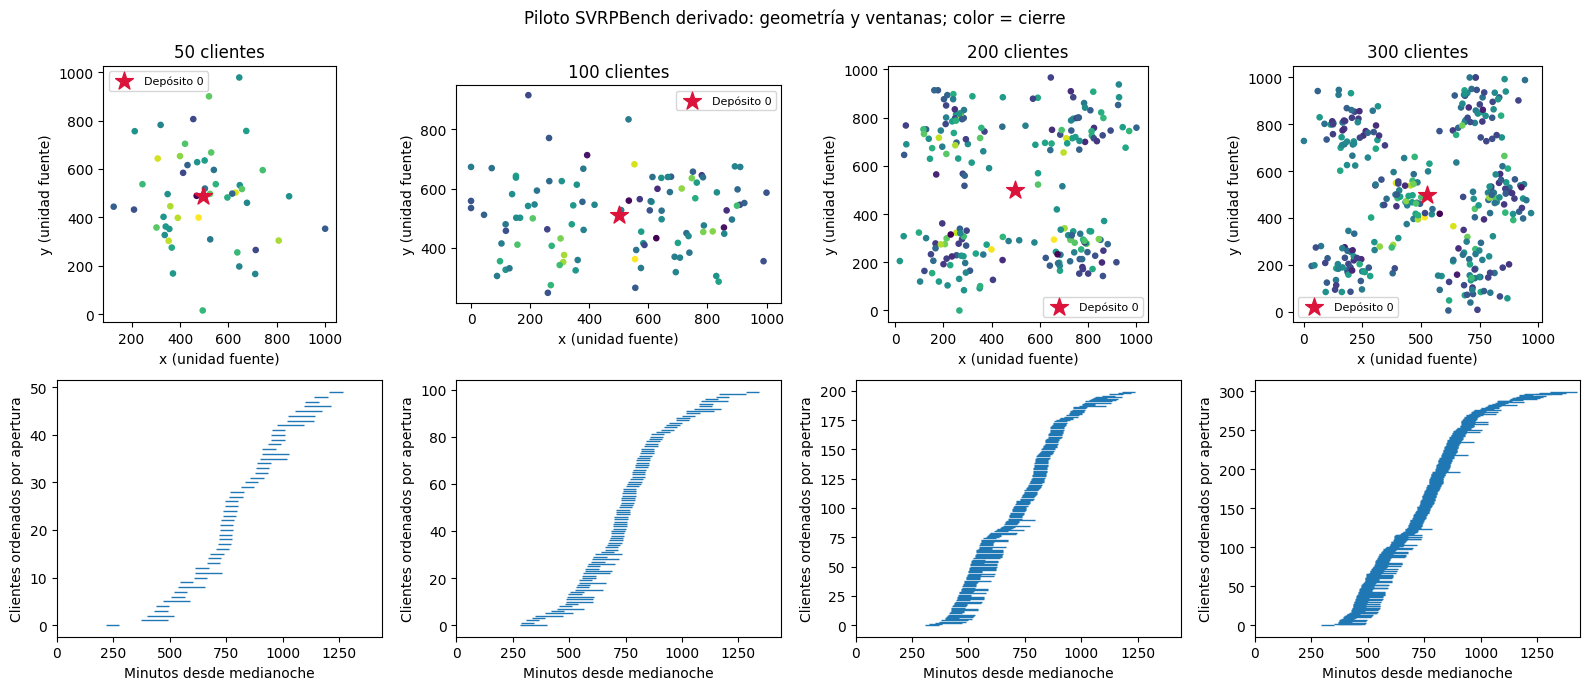

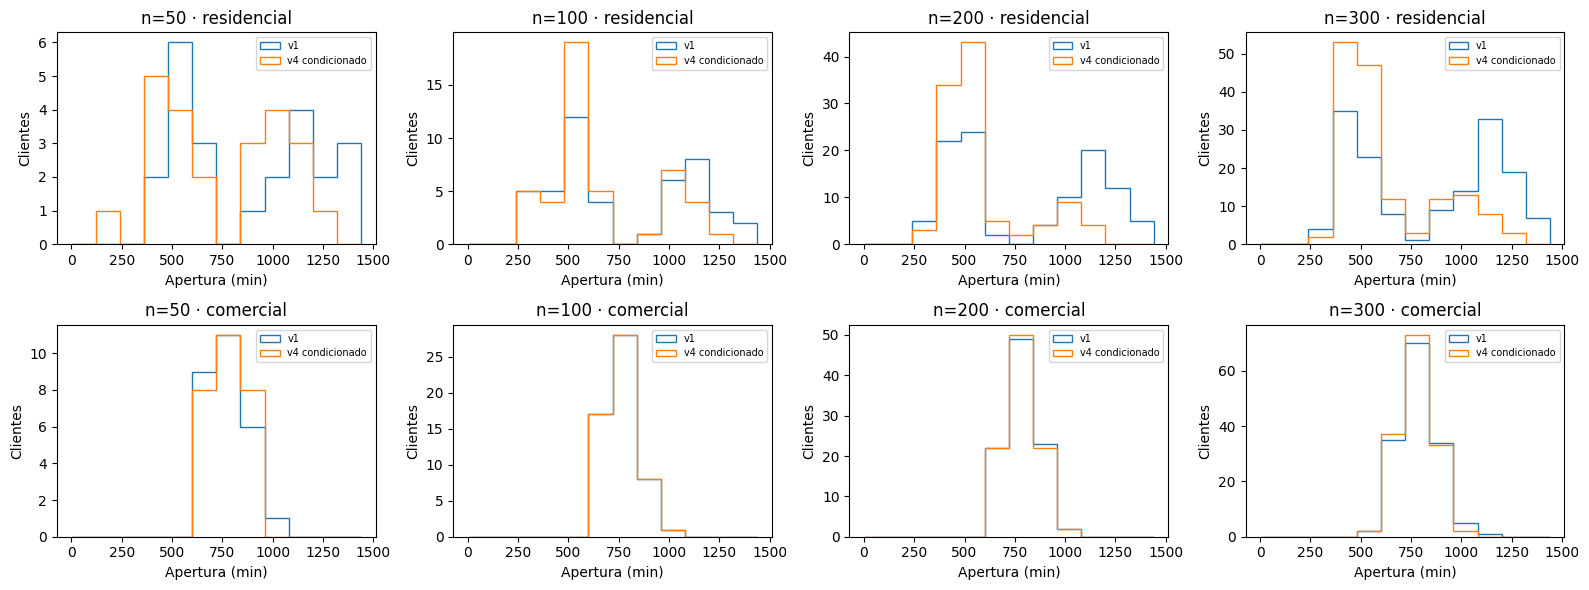

In [33]:
fig, axes = plt.subplots(2,len(instances),figsize=(4*len(instances),7),squeeze=False)
for col,x in enumerate(instances):
    ax=axes[0,col]
    points=ax.scatter(x.locations[1:,0],x.locations[1:,1],c=x.windows[1:,1],s=14,cmap='viridis')
    ax.scatter(*x.locations[0],marker='*',s=180,c='crimson',label='Depósito 0')
    ax.set(title=f'{x.n} clientes',xlabel='x (unidad fuente)',ylabel='y (unidad fuente)',aspect='equal')
    ax.legend(fontsize=8)
    idx=np.argsort(x.windows[1:,0])+1
    axes[1,col].hlines(np.arange(x.n),x.windows[idx,0],x.windows[idx,1],lw=1)
    axes[1,col].set(xlabel='Minutos desde medianoche',ylabel='Clientes ordenados por apertura',xlim=(0,1440))
fig.suptitle('Piloto SVRPBench derivado: geometría y ventanas; color = cierre')
fig.tight_layout()
plt.show()
# Histograma de aperturas, antes/después y por tipo: diagnóstico, no criterio de selección.
fig,axes=plt.subplots(2,len(instances),figsize=(4*len(instances),6),squeeze=False)
for col,x in enumerate(instances):
    parent=p.freeze_instance(json.loads((BANK/f'sources/reconstructed_v1_n{x.n:04d}.json').read_text()))
    types=np.array(x.provenance['customer_types'])
    for row,(kind,label) in enumerate([(0,'residencial'),(1,'comercial')]):
        mask=types==kind
        axes[row,col].hist(parent.windows[mask,0],bins=np.arange(0,1441,120),histtype='step',label='v1')
        axes[row,col].hist(x.windows[mask,0],bins=np.arange(0,1441,120),histtype='step',label='v4 condicionado')
        axes[row,col].set(title=f'n={x.n} · {label}',xlabel='Apertura (min)',ylabel='Clientes')
        axes[row,col].legend(fontsize=7)
fig.tight_layout();plt.show()

## 8. Reglas de evaluación comunes
`Traffic` adapta las ecuaciones del **código oficial en minutos**, sin multiplicar accidentes para
hacerlos visibles. En esta parametrización los accidentes pueden ser raros; eso se informa, no se
corrige después de ver resultados. No se reutiliza una matriz estocástica almacenada y se le vuelve a
sumar ruido: los tiempos se calculan desde distancias euclídeas flotantes y el reloj de cada vehículo.

Los números aleatorios se indexan por instancia, escenario, arco dirigido y minuto. Así no dependen
del método ni del orden de evaluación. Esta es una adaptación CRN explícita; no se afirma que reproduzca
bit a bit las simulaciones del artículo, ni que implemente correlaciones espaciales o propiedad FIFO.

Dos políticas comunes: `fixed_order` (esperar apertura y conservar orden) y `causal_edd` (si el próximo
cliente se proyecta tarde, priorizar un pendiente aún alcanzable cuyo cierre sea más próximo). Esta
segunda política es una decisión experimental de la tesis, no una política oficial de SVRPBench.
Sólo ve reloj actual y tiempos esperados; nunca consulta escenarios futuros. No cambia asignación
vehículo-cliente ni añade vehículos. La tardanza ya ocurrida sigue contándose.

Se reportan por separado tiempo de viaje, espera, tardanza, regreso tardío, flota y factibilidad estricta.
CVaR se aplica al tiempo de viaje. No se inventa un peso monetario de tardanza ni una mejora mínima
favorable al método. Antes de entrenar HBG se fijará el objetivo completo que evite premiar rutas baratas
pero infactibles. `net_execution_delta_minutes` es C−c (puede ser negativo), no costo óptimo de recurso.

In [34]:
traffic = p.Traffic(**CONFIG['traffic'])
# Pruebas manuales independientes de los datos descargados.
tiny = p.freeze_instance(dict(instance_id='manual',depot_indices=[0],locations=[[0,0],[3,0],[6,0]],
    demands=[0,0,1],capacities=[5],windows=[[0,100],[5,10],[0,100]],appear_times=[0,0,0],
    provenance={'kind':'manual_validation'}))
r=p.simulate(tiny,[[1,2]],1,p.Traffic(mode='no_noise'))
assert r['travel_minutes']==12 and r['waiting_minutes']==2 and r['strict_feasible']
# Control negativo: misma geometría, plazo de retorno imposible (6+6 > 8).
negative = tiny.payload(); negative['windows'][0] = [0,8]
negative = p.freeze_instance(negative)
assert not p.simulate(negative,[[1,2]],1,p.Traffic(mode='no_noise'))['strict_feasible']
assert p.audit_instance(negative)['proven_infeasible_by_lower_bound']
assert p.empirical_cvar([1,2,3,10],.5)==6.5
assert np.isclose(p.empirical_cvar([1,2,3,10],.2),15.2/3.2)
try: p.validate_routes(tiny,[[2]])
except ValueError: pass
else: raise AssertionError('No detectó un cliente de demanda cero omitido.')
a=p.travel_time(20,480,0,1,'manual',22,traffic)
_ = p.travel_time(20,500,1,2,'manual',33,traffic)
assert a==p.travel_time(20,480,0,1,'manual',22,traffic)
print('Casos manuales y CRN: correctos.')

Casos manuales y CRN: correctos.


## 9. Una solución diagnóstica por tamaño
Primero se verifica y evalúa la **solución testigo** como control positivo; sus resultados se guardan
por separado y nunca participan en una clasificación de métodos. No se exige FR estocástica=1.

La heurística ordena por cierre y asigna por tardanza proyectada e incremento de recorrido, con
restricciones de capacidad. **No es OR-Tools, HBG, GFACS ni una reproducción del baseline del artículo.**
Sirve para probar end-to-end el contrato. Puede producir una ruta estructuralmente válida que incumpla
ventanas; se mostrará como tal, incluyendo su factibilidad nominal. Si su FR es cero mientras el testigo
es nominalmente factible, la instancia sí admite una solución y el fallo pertenece a la heurística.
Las dos políticas se evalúan sin escoger ganadora utilizando evaluación.
Cada tamaño guarda un bloque sellado al finalizar, de modo que una interrupción no borre los anteriores.

In [35]:
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8]
RUN_ROOT = WORK/'runs'/BANK_ID/RUN_ID
RUN_ROOT.mkdir(parents=True,exist_ok=False)
all_summaries=[]
quality_controls=[]
solutions={}
for x in instances:
    out=RUN_ROOT/f'n{x.n:04d}'
    out.mkdir()
    scenario_file=json.loads((BANK/f'scenarios/n{x.n:04d}.json').read_text())
    certificate=json.loads((BANK/f'certificates/n{x.n:04d}.json').read_text())
    nominal_check=p.verify_certificate(x,certificate,traffic)
    control,control_records=p.evaluate(x,certificate['routes'],scenario_file['evaluation'],
                                      traffic,'fixed_order',CONFIG['alpha_cvar'])
    control.update(method='feasibility_witness',role='quality_control_only',n=x.n,
                   nominal_strict_feasible=nominal_check['strict_feasible'])
    quality_controls.append(control)
    p.write_json(out/'quality_control_summary.json',control)
    pd.DataFrame(control_records).to_csv(out/'quality_control_scenarios.csv',index=False)
    print(x.n,'testigo nominal: factible; FR estocástica:',control['scenario_strict_feasibility'],flush=True)
    try:
        started=time.perf_counter()
        routes=p.diagnostic_greedy(x,traffic)
        solve_seconds=time.perf_counter()-started
    except ValueError as exc:
        p.write_json(out/'failure.json',{'instance_id':x.instance_id,'method':'diagnostic_greedy',
            'status':'construction_failed','message':str(exc),'not_a_proof_of_infeasibility':True})
        p.seal_bundle(out)
        if DRIVE_ROOT: p.sync_verified(out,DRIVE_ROOT/'runs'/BANK_ID/RUN_ID/out.name)
        print(x.n,'construcción falló; el fallo se conserva.'); continue
    solutions[x.n]=routes
    p.write_json(out/'solution.json',{'method':'diagnostic_greedy','routes':routes,
        'instance_sha256':x.sha,'bank_id':BANK_ID,'solve_seconds':solve_seconds,
        'information_used':'instance and expected times only; no evaluation scenarios or certificate routes'})
    for policy in CONFIG['policies']:
        nominal_spec=p.Traffic(**(CONFIG['traffic'] | {'mode':'nominal_mean'}))
        nominal=p.simulate(x,routes,0,nominal_spec,policy)
        summary,records=p.evaluate(x,routes,scenario_file['evaluation'],traffic,policy,CONFIG['alpha_cvar'])
        summary.update(method='diagnostic_greedy',solve_seconds=solve_seconds,role='development_only',
                       nominal_strict_feasible=nominal['strict_feasible'])
        all_summaries.append(summary)
        p.write_json(out/f'{policy}_summary.json',summary)
        pd.DataFrame(records).to_csv(out/f'{policy}_scenarios.csv',index=False)
        example=p.simulate(x,routes,scenario_file['evaluation'][0],traffic,policy,trace=True)
        p.write_json(out/f'{policy}_first_trace.json',example)
        print(x.n,policy,'factibilidad nominal:',nominal['strict_feasible'],
              'FR estocástica:',round(summary['scenario_strict_feasibility'],4),
              'viaje medio:',round(summary['mean_travel_minutes'],2),flush=True)
    p.write_json(out/'environment.json',ENVIRONMENT)
    p.seal_bundle(out)
    if DRIVE_ROOT: p.sync_verified(out,DRIVE_ROOT/'runs'/BANK_ID/RUN_ID/out.name)
summary_table=pd.DataFrame(all_summaries)
control_table=pd.DataFrame(quality_controls)
print('Controles de calidad (no comparadores):')
display(control_table[['n','nominal_strict_feasible','scenario_strict_feasibility']])
print('Heurística diagnóstica:')
display(summary_table)
print('Directorio de resultados:',RUN_ROOT)

50 testigo nominal: factible; FR estocástica: 1.0
50 fixed_order factibilidad nominal: False FR estocástica: 0.0 viaje medio: 10849.79
50 causal_edd factibilidad nominal: False FR estocástica: 0.0 viaje medio: 10923.06
100 testigo nominal: factible; FR estocástica: 1.0
100 fixed_order factibilidad nominal: True FR estocástica: 1.0 viaje medio: 19603.56
100 causal_edd factibilidad nominal: True FR estocástica: 1.0 viaje medio: 19603.56
200 testigo nominal: factible; FR estocástica: 0.953125
200 fixed_order factibilidad nominal: True FR estocástica: 1.0 viaje medio: 41123.56
200 causal_edd factibilidad nominal: True FR estocástica: 1.0 viaje medio: 41123.56
300 testigo nominal: factible; FR estocástica: 1.0
300 fixed_order factibilidad nominal: True FR estocástica: 0.9961 viaje medio: 58916.89
300 causal_edd factibilidad nominal: True FR estocástica: 0.9961 viaje medio: 58916.89
Controles de calidad (no comparadores):


,n,nominal_strict_feasible,scenario_strict_feasibility
0,50,True,1.000000
1,100,True,1.000000
2,200,True,0.953125
3,300,True,1.000000


Heurística diagnóstica:


,instance_id,instance_sha256,policy,scenarios,alpha,mean_travel_minutes,cvar_travel_minutes,cost_variance_population,scenario_strict_feasibility,mean_customer_violation_fraction,mean_lateness_minutes,mean_depot_overtime_minutes,used_vehicles,evaluation_seconds,method,solve_seconds,role,nominal_strict_feasible
0,dev_tw_n50_i0_cw_v3_joint005,27f2c447bd200284b6b6b8dd98f917e3a283fec26aec64...,fixed_order,256,0.95,10849.791120,10850.370021,0.081822,0.000000,0.08,210.569850,19.876858,12,1.030754,diagnostic_greedy,0.005624,development_only,False
1,dev_tw_n50_i0_cw_v3_joint005,27f2c447bd200284b6b6b8dd98f917e3a283fec26aec64...,causal_edd,256,0.95,10923.061411,10923.637725,0.078158,0.000000,0.08,576.958233,112.508947,12,1.106779,diagnostic_greedy,0.005624,development_only,False
2,dev_tw_n100_i0_cw_v3,9af29133be5fc338e6e5de83e9e7d53edc7991295004ef...,fixed_order,256,0.95,19603.563568,19604.428411,0.156915,1.000000,0.00,0.000000,0.000000,25,2.145945,diagnostic_greedy,0.022326,development_only,True
3,dev_tw_n100_i0_cw_v3,9af29133be5fc338e6e5de83e9e7d53edc7991295004ef...,causal_edd,256,0.95,19603.563568,19604.428411,0.156915,1.000000,0.00,0.000000,0.000000,25,2.270354,diagnostic_greedy,0.022326,development_only,True
4,dev_tw_n200_i0_cw_v3,68df88a390f0abff057b957a7fed6d968c49eaca90c181...,fixed_order,256,0.95,41123.557126,41124.831723,0.285600,1.000000,0.00,0.000000,0.000000,42,4.216729,diagnostic_greedy,0.081736,development_only,True
5,dev_tw_n200_i0_cw_v3,68df88a390f0abff057b957a7fed6d968c49eaca90c181...,causal_edd,256,0.95,41123.557126,41124.831723,0.285600,1.000000,0.00,0.000000,0.000000,42,4.483970,diagnostic_greedy,0.081736,development_only,True
6,dev_tw_n300_i0_cw_v3,8a8356445234902ced061220b435c5d90c942c32488a61...,fixed_order,256,0.95,58916.888530,58926.663071,51.818796,0.996094,0.00,0.000000,0.400583,58,6.564267,diagnostic_greedy,0.184427,development_only,True
7,dev_tw_n300_i0_cw_v3,8a8356445234902ced061220b435c5d90c942c32488a61...,causal_edd,256,0.95,58916.888530,58926.663071,51.818796,0.996094,0.00,0.000000,0.400583,58,6.922328,diagnostic_greedy,0.184427,development_only,True


Directorio de resultados: /content/TESIS_EHBG_FACS/runs/pilot00_280553a33c2ab594/20260917T021417Z_665a3a34


## 10. Rutas y costos: lectura descriptiva
Los tiempos medidos aquí describen esta sesión y hardware, no una comparación de métodos. Con una
sola instancia por escala no se calculan ANOVA, Friedman ni p-valores. En ejecuciones largas, aumentar
escenarios sirve para precisión Monte Carlo, no reemplaza las instancias independientes.

El generador oficial reutiliza mapas en varias realizaciones. El campo `geometry_group_sha256`
identifica la geometría de cada caso: cambiar ventanas, semillas o tráfico sobre el mismo mapa no
crea una nueva unidad independiente ni permite repartir ese mapa entre train/validation/test.

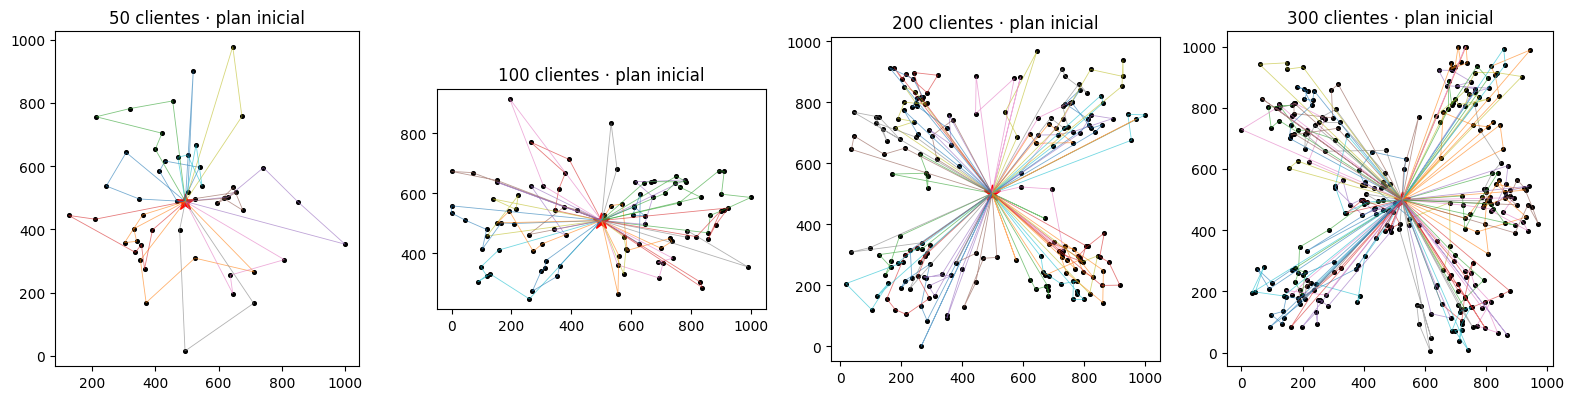

Resultados y gráfico verificados en: /content/drive/MyDrive/TESIS-EHBG-FACS/runs/pilot00_280553a33c2ab594/20260917T021417Z_665a3a34


In [36]:
fig,axes=plt.subplots(1,len(instances),figsize=(4*len(instances),4),squeeze=False)
for col,x in enumerate(instances):
    ax=axes[0,col]
    for route in solutions.get(x.n,[]):
        if route:
            coords=x.locations[[0]+route+[0]]
            ax.plot(coords[:,0],coords[:,1],lw=.6,alpha=.6)
    ax.scatter(x.locations[1:,0],x.locations[1:,1],s=7,c='black')
    ax.scatter(*x.locations[0],marker='*',s=140,c='red')
    ax.set(title=f'{x.n} clientes · plan inicial',aspect='equal')
fig.tight_layout(); plt.show()
REPORT=RUN_ROOT/'report'; REPORT.mkdir()
fig.savefig(REPORT/'routes.png',dpi=160,bbox_inches='tight')
summary_table.to_csv(REPORT/'summary.csv',index=False)
control_table.to_csv(REPORT/'quality_controls.csv',index=False)
p.write_json(REPORT/'run.json',{'run_id':RUN_ID,'bank_id':BANK_ID,
    'bank_manifest_sha256':p.verify_bundle(BANK),'role':'development_only',
    'environment':ENVIRONMENT,'hypothesis_testing':False})
p.seal_bundle(REPORT)
if DRIVE_ROOT:
    p.sync_verified(REPORT,DRIVE_ROOT/'runs'/BANK_ID/RUN_ID/'report')
    print('Resultados y gráfico verificados en:',DRIVE_ROOT/'runs'/BANK_ID/RUN_ID)
else:
    print('Resultados verificados en disco temporal de Colab:',REPORT)

## 11. Contrato para los métodos siguientes
Todos deben cargar el mismo banco sellado, mantener depósito/flota/clientes/unidades y devolver
`routes`: una lista por vehículo, sin incluir el depósito. Las listas vacías representan vehículos
no usados. El evaluador añade salida y regreso al depósito y comprueba la cobertura completa.
No aceptar directamente las métricas que reporte el solver: volver a evaluar sus rutas aquí.
`load_bank` comprueba manifiesto, versión, código, tamaños y certificados nominales. Los certificados
son para auditoría: no entregarlos a ningún método como entrenamiento, solución inicial ni presupuesto
de búsqueda gratuito. V1, v2, v3 y v4 tienen IDs y hashes diferentes; no combinar sus resultados.

```python
import sys
sys.path.insert(0, str(BANK / 'code'))  # su __pycache__ no invalida el sello
import svrplab_pilot as shared
instances = shared.load_bank(BANK)
# routes = mi_metodo(instance, datos_permitidos, presupuesto)
shared.validate_routes(instance, routes)
# Usar train/selection para entrenar y seleccionar, evaluation sólo para informar.
summary, raw = shared.evaluate(instance, routes, evaluation_seeds, traffic, 'causal_edd')
```

Antes de comparar AM/POMO/ACO/HBG: fijar presupuestos de construcción/búsqueda, reportar entrenamiento
y tuning por separado, registrar hardware, y comprobar máscaras/objetivo con los casos manuales.
No otorgar más vehículos, más escenarios de selección o más tiempo al método propuesto. Si se utilizan
presupuestos largos, mostrar curvas calidad-tiempo y cantidades de evaluaciones, sin imponer ahora
un umbral de milisegundos ni un porcentaje de mejora sin justificación operativa.

**Pendientes científicos visibles:** calibración de congestión/accidentes, sensibilidad a ventanas
reconstruidas, objetivo sensible al riesgo con tratamiento de fallos, integración RL4CO, baselines y
entrenamiento HBG. ENN continúa como extensión opcional. El siguiente notebook debe implementar un
comparador y usar este contrato, no regenerar sus propias instancias.

**Orden de avance:** (1) acta de aceptación de cuatro tamaños en Colab; (2) implementar y depurar
cada comparador sobre este banco; (3) piloto ampliado con geometrías independientes, separado del
test final, para estimar variabilidad y costo; (4) fijar número de geometrías, escenarios y semillas
por precisión/potencia y presupuesto, sin elegirlos por significancia observada; (5) congelar métodos,
presupuestos, generador y análisis; (6) ejecutar el test final común. Los contrastes serán pareados por
geometría/instancia y respetarán el anidamiento de semillas y escenarios. No hay todavía un N final
justificado. El certificado es de existencia, no de optimalidad: no permite calcular un gap al óptimo.

### Fuentes
- Heakl et al., [SVRPBench](https://arxiv.org/abs/2505.21887), ecuaciones de tráfico y métricas.
- [Código SVRPBench fijado](https://github.com/yehias21/svrpbench/tree/9fd5737ae598e1667ae94907f9c45224c501c84b).
- [Dataset](https://huggingface.co/datasets/MBZUAI/svrp-bench).
- [OR-Tools: ventanas y dimensiones de tiempo](https://developers.google.com/optimization/routing/vrptw).
- [OR-Tools: límites y estados de búsqueda](https://developers.google.com/optimization/routing/routing_options).
- Gendreau, Laporte y Séguin (1996), *Stochastic vehicle routing*: recurso dependiente de la información disponible.
- Rockafellar y Uryasev (2000), *Optimization of Conditional Value-at-Risk*: CVaR por escenarios.
- [Límites de Colab](https://research.google.com/colaboratory/faq.html): GPU disponible y duración variables.